In [1]:
# Select physical GPU 1 and hide the rest
import os
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = "1"   # now "cuda:0" == physical GPU 1

In [ ]:
#  Cell 1: Import necessary libraries

import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE
from keras.layers import Dense, LSTM, Dropout, Bidirectional
from keras.models import Sequential
import pennylane as qml
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

import time
import numpy as np
import pandas as pd
import pennylane as qml

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

2025-12-13 23:25:39.941391: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-12-13 23:25:39.973419: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-12-13 23:25:39.973452: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-12-13 23:25:39.974393: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-12-13 23:25:39.980062: I tensorflow/core/platform/cpu_feature_guar

In [3]:
#  Cell 2: Load Dataset
data_path = '/home/g202319370/mydesktop/FILES/distributed_computing/csv/OD10cleaned_intrusion_dataset.csv'
df = pd.read_csv(data_path)

In [ ]:
# Get Unique Labels and Their Counts
label_counts = df["Label"].value_counts()

# Print Count of Each Label
print("Label Counts in the Dataset:\n", label_counts)

# Print Total Number of Unique Labels
print("\n Total Number of Unique Labels:", len(label_counts))

🔹 Label Counts in the Dataset:
 Label
SYN Floods                                                   175694
Fragmented Packet Attacks                                    125903
Distributed_denial-of-service                                100090
Man-in-the-middle                                             87852
BENIGN                                                        68004
Brute Force Attacks                                           63663
ARP_Spoofing                                                  61489
Slow_HTTP_attack                                              45880
Time-based SQL Injection                                      16638
Remote Code Execution via Unrestricted File Upload access     13797
Name: count, dtype: int64

 Total Number of Unique Labels: 10


In [5]:
from sklearn.utils import resample
import pandas as pd

# Define equal target size for each class
num_classes = 5
target_size = 200_000 // num_classes  # 40,000 per class

# List to store balanced subsets
balanced_dfs = []

# Loop over each class
for attack in ["SYN Floods", "Fragmented Packet Attacks", 
               "Distributed_denial-of-service", 
               "Man-in-the-middle", "BENIGN"]:
    
    df_attack = df[df["Label"] == attack]
    
    # Upsample or downsample to target_size
    if len(df_attack) > target_size:
        df_attack = df_attack.sample(n=target_size, random_state=42)
    else:
        df_attack = resample(df_attack, replace=True, 
                             n_samples=target_size, random_state=42)
    
    balanced_dfs.append(df_attack)

# Combine all balanced data
df = pd.concat(balanced_dfs)

# Shuffle dataset
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

# Print new dataset distribution
print(f"Balanced dataset size: {df.shape[0]}")
print("Balanced Class Distribution:\n", df["Label"].value_counts())

Balanced dataset size: 200000
Balanced Class Distribution:
 Label
Distributed_denial-of-service    40000
Fragmented Packet Attacks        40000
Man-in-the-middle                40000
SYN Floods                       40000
BENIGN                           40000
Name: count, dtype: int64


In [ ]:
# Define a mapping from long names to shorter ones
label_mapping = {
    "Fragmented Packet Attacks": "FragPkt",
    "Distributed_denial-of-service": "DDoS",
    "Man-in-the-middle": "MITM",
    "SYN Floods": "SYN",
    "BENIGN": "Normal"
}

# Apply the mapping safely 
df["Label"] = df["Label"].replace(label_mapping)

# Check results
print("Renamed Class Distribution:\n", df["Label"].value_counts())
print("Unique labels after renaming:", df["Label"].unique())


Renamed Class Distribution:
 Label
DDoS       40000
FragPkt    40000
MITM       40000
SYN        40000
Normal     40000
Name: count, dtype: int64
Unique labels after renaming: ['DDoS' 'FragPkt' 'MITM' 'SYN' 'Normal']


In [ ]:
# === Cell 0: Toolbox & House Style ( Q=5 pipeline) ================
from pathlib import Path
import time, csv, io, math, json, gc, os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle, FancyArrow, Circle
from matplotlib.lines import Line2D
from sklearn.metrics import (
    confusion_matrix, f1_score, accuracy_score, roc_auc_score,
    average_precision_score, matthews_corrcoef, precision_recall_curve,
    roc_curve, classification_report, log_loss
)
from sklearn.preprocessing import label_binarize
from sklearn.decomposition import PCA


RUN_TAG = "reduced"   
ROOT     = Path(f"FIVEQUBITS_{RUN_TAG}")

# ---------- Base folders ----------
RES_DIR  = ROOT / "results"
FIG_DIR  = ROOT / "figs"
PRED_DIR = ROOT / "preds"
for d in (RES_DIR, FIG_DIR, PRED_DIR):
    d.mkdir(parents=True, exist_ok=True)

MASTER_CSV    = RES_DIR / "master_results.csv"
FIG_MANIFEST  = RES_DIR / "figure_manifest.csv"

# ---------- House style / palette ----------
mpl.rcParams.update({
    "font.size": 12,
    "font.family": "DejaVu Sans",
    "figure.dpi": 150,
    "axes.spines.top": False,
    "axes.spines.right": False
})

PALETTE = {
    "wire": "#444444",
    "annot": "#212121",
    "measure_edge": "#424242",
    "amp_fill": "#e3f2fd", "amp_edge": "#1976d2",
    "vqc_fill": "#fff3e0", "vqc_edge": "#ef6c00",
    "enc_fill": "#e8f5e9", "enc_edge": "#2e7d32",
    "rot_fill": "#f3e5f5", "rot_edge": "#6a1b9a",
    "cnot_line": "#0d47a1"
}

BASE_CLASS_COLORS = {
    "DDoS": "#1976d2",
    "FragPkt": "#ef6c00",
    "MITM": "#2e7d32",
    "Normal": "#c62828",
    "SYN": "#6a1b9a",
}
FALLBACK_COLORS = ["#1976d2", "#ef6c00", "#2e7d32", "#c62828", "#6a1b9a", "#00838f", "#5d4037"]

def class_color_map(class_names):
    cmap, k = {}, 0
    for name in class_names:
        cmap[name] = BASE_CLASS_COLORS.get(name, FALLBACK_COLORS[k % len(FALLBACK_COLORS)])
        if name not in BASE_CLASS_COLORS: k += 1
    return cmap

# ---------- File/figure helpers ----------
def _ensure_header(path: Path, header: list[str]):
    if not path.exists():
        with open(path, "w", newline="", encoding="utf-8") as f:
            csv.writer(f).writerow(header)

def log_figure(dataset, model, qubits, seed_or_tag, plot_type, stem, png_path, svg_path):
    header = ["dataset","model","qubits","seed_or_tag","plot_type","stem","path_png","path_svg","timestamp"]
    _ensure_header(FIG_MANIFEST, header)
    with open(FIG_MANIFEST, "a", newline="", encoding="utf-8") as f:
        csv.writer(f).writerow([dataset, model, qubits, seed_or_tag, plot_type, stem, str(png_path), str(svg_path), int(time.time())])

def savefig_both(fig: mpl.figure.Figure, out_stem: Path, meta: dict | None = None, show: bool = True):
    out_stem.parent.mkdir(parents=True, exist_ok=True)
    png = out_stem.with_suffix(".png")
    svg = out_stem.with_suffix(".svg")
    fig.tight_layout()
    fig.savefig(png, dpi=600, bbox_inches="tight")
    fig.savefig(svg, bbox_inches="tight")
    if show:
        display(fig)
    plt.close(fig)
    if meta is not None:
        log_figure(meta["dataset"], meta["model"], meta["qubits"], meta["seed_or_tag"],
                   meta["plot_type"], out_stem.name, png, svg)

def fig_stem(dataset: str, model: str, qubits: int, tag: str, name: str) -> Path:
    return FIG_DIR / dataset / model / f"Q{qubits}" / tag / name

def preds_dir(dataset: str, model: str, qubits: int, seed: int) -> Path:
    return PRED_DIR / dataset / model / f"Q{qubits}" / f"seed_{seed}"

def shared_dir_vqc(dataset: str, model: str, qubits: int) -> Path:
    return RES_DIR / "shared" / dataset / model / f"Q{qubits}" / "vqc"

def shared_dir_feats(dataset: str, model: str, qubits: int) -> Path:
    return RES_DIR / "shared" / dataset / model / f"Q{qubits}" / "features"

def cm_blue():
    b = tuple(int(PALETTE["amp_edge"].lstrip("#")[i:i+2], 16)/255 for i in (0,2,4))
    return LinearSegmentedColormap.from_list("cm_blue", [(1,1,1), b])

# ---------- Metrics ----------
def ece_top1(y_true: np.ndarray, y_proba: np.ndarray, n_bins: int = 15) -> float:
    conf = y_proba.max(axis=1)
    pred = y_proba.argmax(axis=1)
    corr = (pred == y_true).astype(float)
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        m = (conf > bins[i]) & (conf <= bins[i+1])
        if np.any(m):
            ece += m.mean() * abs(corr[m].mean() - conf[m].mean())
    return float(ece)

def macro_auprc(y_true: np.ndarray, y_proba: np.ndarray, classes: np.ndarray) -> float:
    Y = label_binarize(y_true, classes=classes)
    vals = []
    for k in range(Y.shape[1]):
        vals.append(average_precision_score(Y[:, k], y_proba[:, k]))
    return float(np.mean(vals))

# ---------- Model-size helpers ----------
def count_pca_params(pca):
    comps = getattr(pca, "components_", None)
    meanv = getattr(pca, "mean_", None)
    if comps is None or meanv is None:
        return {"non_trainable": 0, "size_mb": 0.0, "n_components": None, "n_features": None}
    n_comp, n_feat = comps.shape
    cnt = comps.size + meanv.size
    sz_mb = (comps.nbytes + meanv.nbytes) / (1024**2)
    return {"non_trainable": int(cnt), "size_mb": float(sz_mb), "n_components": n_comp, "n_features": n_feat}

def count_vqc_params(weights_np):
    if weights_np is None:
        return {"trainable": 0, "size_mb": 0.0, "shape": None}
    cnt = int(np.prod(weights_np.shape))
    sz_mb = weights_np.nbytes / (1024**2)
    return {"trainable": cnt, "size_mb": float(sz_mb), "shape": tuple(weights_np.shape)}

def count_tabnet_params(tabnet_model):
    from torch import nn
    trainable = 0
    frozen = 0
    size_bytes = 0
    for p in tabnet_model.network.parameters():
        n = p.numel()
        size_bytes += n * p.element_size()
        if p.requires_grad: trainable += n
        else:               frozen    += n
    return {
        "trainable": int(trainable),
        "non_trainable": int(frozen),
        "total": int(trainable + frozen),
        "size_mb": float(size_bytes / (1024**2))
    }

def print_model_size(pca, vqc_weights_np, tabnet_model, label="Quantum pipeline (PCA → VQC → TabNet)"):
    p_pca = count_pca_params(pca)
    p_vqc = count_vqc_params(vqc_weights_np)
    p_tbn = count_tabnet_params(tabnet_model)
    total_params = p_pca["non_trainable"] + p_vqc["trainable"] + p_tbn["total"]
    total_size_mb = p_pca["size_mb"] + p_vqc["size_mb"] + p_tbn["size_mb"]

    print("\n" + "="*72)
    print(f"{label}")
    print("-"*72)
    print(f"PCA (non-trainable):   params={p_pca['non_trainable']:,}  "
          f"shape=({p_pca['n_components']}, {p_pca['n_features']})  size={p_pca['size_mb']:.3f} MB")
    print(f"VQC θ (trainable):     params={p_vqc['trainable']:,}      "
          f"shape={p_vqc['shape']}  size={p_vqc['size_mb']:.3f} MB")
    print(f"TabNet:                trainable={p_tbn['trainable']:,}  "
          f"non-trainable={p_tbn['non_trainable']:,}  total={p_tbn['total']:,}  size={p_tbn['size_mb']:.3f} MB")
    print("-"*72)
    print(f"TOTAL:                 params={total_params:,}  size={total_size_mb:.3f} MB")
    print("="*72 + "\n")

In [ ]:
# === Cell 1: RUN Q=5 (shared VQC, cached features, sweep TabNet)
import pennylane as qml
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.decomposition import PCA
from pytorch_tabnet.tab_model import TabNetClassifier
from torch import nn, optim
from pathlib import Path
from sklearn.metrics import log_loss
import torch, time, os, csv, gc
import numpy as np
import pandas as pd

assert 'df' in globals(), "pandas DataFrame named `df`."

# ---------- Config ----------
DATASET = "OD-IDS2022"
MODEL   = "QuantumTabNet"
Q = 5
L = 1
TARGET_DIM = 2**Q  # 32

MODEL_SEEDS = [101, 202, 402]
SEED_FOR_CURVES = 101

SPLIT_SEED, PCA_SEED, SUBSET_SEED = 42, 42, 42
TRAIN_FRAC, VAL_FRAC, TEST_FRAC = 0.80, 0.10, 0.10

# Force full pipeline timings even if caches exist
FORCE_VQC_PRETRAIN = True
FORCE_REENCODE     = True

# One-time VQC pretrain budget (balanced across classes)
PRETRAIN_BUDGET = 3000   # 5 classes → 600 per class (cap if minority smaller)
VQC_PRE_EPOCHS  = 15
VQC_BATCH       = 256
ENC_BATCH       = 4096   # big batch for fast GPU encoding

# Tiny TabNet sweep for seed=101 (pick best, reuse config for other seeds)
DO_SWEEP = True
SWEEP_GRID = [
    dict(n_d=32, n_a=32, n_steps=4, gamma=1.0,  lambda_sparse=1e-5, mask_type="entmax"),
    dict(n_d=32, n_a=32, n_steps=6, gamma=1.5,  lambda_sparse=1e-4, mask_type="entmax"),
    dict(n_d=48, n_a=48, n_steps=4, gamma=1.5,  lambda_sparse=1e-5, mask_type="sparsemax"),
    dict(n_d=48, n_a=48, n_steps=6, gamma=1.0,  lambda_sparse=1e-4, mask_type="sparsemax"),
]
MAX_EPOCHS_TBN   = 60
PATIENCE_TBN     = 15
LR_TBN           = 2e-3
WEIGHT_DECAY_TBN = 1e-4

# ---------- Paths ----------
VQC_DIR   = shared_dir_vqc(DATASET, MODEL, Q);    VQC_DIR.mkdir(parents=True, exist_ok=True)
FEAT_DIR  = shared_dir_feats(DATASET, MODEL, Q);  FEAT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR = RES_DIR / "models" / DATASET / MODEL / f"Q{Q}"; MODEL_DIR.mkdir(parents=True, exist_ok=True)
TRAINHIST_DIR = RES_DIR / "training_history" / DATASET / MODEL / f"Q{Q}"; TRAINHIST_DIR.mkdir(parents=True, exist_ok=True)

def set_seed(seed: int):
    np.random.seed(seed)
    torch.manual_seed(seed)

def get_peak_mem_mb() -> float:
    try:
        import resource as _res
        return _res.getrusage(_res.RUSAGE_SELF).ru_maxrss / 1024.0
    except Exception:
        import psutil
        return psutil.Process(os.getpid()).memory_info().rss / (1024**2)

def l2_normalize_rows(A: np.ndarray, eps: float = 1e-12) -> np.ndarray:
    n = np.maximum(np.linalg.norm(A, axis=1, keepdims=True), eps)
    return (A / n).astype(np.float64)

def balanced_subset_indices(y_train: np.ndarray, budget: int, seed: int) -> np.ndarray:
    rng = np.random.default_rng(seed)
    cls, counts = np.unique(y_train, return_counts=True)
    per = int(min(budget // len(cls), counts.min(), len(y_train)))
    return np.hstack([rng.choice(np.where(y_train == c)[0], size=per, replace=False) for c in cls])

def extract_probs_batched(X_amp: np.ndarray, qnode_infer, batch: int = ENC_BATCH, out_dim: int = TARGET_DIM) -> np.ndarray:
    N = X_amp.shape[0]
    out = np.empty((N, out_dim), dtype=np.float32)
    for s in range(0, N, batch):
        xb = torch.from_numpy(X_amp[s:s+batch]).to(dtype=torch.float64).contiguous()
        with torch.no_grad():
            pb = qnode_infer(xb)  # torch [B, out_dim]
            pb = pb.to(torch.float32).cpu().numpy()
        out[s:s+len(pb)] = pb
    return out

# ---------- Device selection (robust) ----------
def _make_device(wires: int):
    if torch.cuda.is_available():
        try:
            return qml.device("lightning.gpu", wires=wires)
        except Exception as e:
            print(f"[WARN] lightning.gpu unavailable ({e}); falling back to CPU backend.")
    for name in ("lightning.qubit", "default.qubit"):
        try:
            return qml.device(name, wires=wires)
        except Exception:
            pass
    raise RuntimeError("No suitable PennyLane device found (tried lightning.gpu, lightning.qubit, default.qubit).")

# ---------- Splits & base preprocess ----------
df_ = df.copy()
df_.drop(columns=['Src IP', 'Dst IP'], inplace=True, errors='ignore')

le = LabelEncoder()
y_all = le.fit_transform(df_['Label'])
class_names = list(le.classes_)

Xdf = df_.drop(columns=['Label'], errors='ignore')
Xdf = Xdf.replace([np.inf, -np.inf], np.nan).select_dtypes(include=[np.number])
X_all = Xdf.to_numpy()

sss_test = StratifiedShuffleSplit(n_splits=1, test_size=TEST_FRAC, random_state=SPLIT_SEED)
tr_idx_all, te_idx = next(sss_test.split(X_all, y_all))
X_rem, y_rem = X_all[tr_idx_all], y_all[tr_idx_all]
X_te_raw, y_te = X_all[te_idx], y_all[te_idx]

val_rel = VAL_FRAC / (1.0 - TEST_FRAC)
sss_val = StratifiedShuffleSplit(n_splits=1, test_size=val_rel, random_state=SPLIT_SEED)
tr_idx, va_idx = next(sss_val.split(X_rem, y_rem))
X_tr_raw, y_tr = X_rem[tr_idx], y_rem[tr_idx]
X_va_raw, y_va = X_rem[va_idx], y_rem[va_idx]
n_train, n_val, n_test = len(y_tr), len(y_va), len(y_te)
print(f"Split sizes → Train={n_train}, Val={n_val}, Test={n_test}")

# Train-only statistics
train_median = np.nanmedian(X_tr_raw, axis=0)
X_tr_raw = np.where(np.isnan(X_tr_raw), train_median, X_tr_raw)
X_va_raw = np.where(np.isnan(X_va_raw), train_median, X_va_raw)
X_te_raw = np.where(np.isnan(X_te_raw), train_median, X_te_raw)

scaler = StandardScaler().fit(X_tr_raw)
X_tr_raw = scaler.transform(X_tr_raw)
X_va_raw = scaler.transform(X_va_raw)
X_te_raw = scaler.transform(X_te_raw)

# PCA to TARGET_DIM
t_pca0 = time.time()
pca = PCA(n_components=min(TARGET_DIM, X_tr_raw.shape[1], max(1, X_tr_raw.shape[0]-1)),
          random_state=PCA_SEED)
X_tr_p = pca.fit_transform(X_tr_raw)
X_va_p = pca.transform(X_va_raw)
X_te_p = pca.transform(X_te_raw)
if X_tr_p.shape[1] < TARGET_DIM:
    pad = TARGET_DIM - X_tr_p.shape[1]
    X_tr_p = np.hstack([X_tr_p, np.zeros((X_tr_p.shape[0], pad))])
    X_va_p = np.hstack([X_va_p, np.zeros((X_va_p.shape[0], pad))])
    X_te_p = np.hstack([X_te_p, np.zeros((X_te_p.shape[0], pad))])
pca_time = time.time() - t_pca0
print(f"[Timing] PCA: {pca_time:.2f}s")

X_tr_amp = l2_normalize_rows(X_tr_p)
X_va_amp = l2_normalize_rows(X_va_p)
X_te_amp = l2_normalize_rows(X_te_p)

# ---------- VQC pretrain once or load ----------
vqc_w_path = VQC_DIR / f"vqc_weights_Q{Q}_L{L}.npy"
vqc_pretrain_time = 0.0  # ensure defined

if vqc_w_path.exists() and not FORCE_VQC_PRETRAIN:
    weights_frozen_np = np.load(vqc_w_path)
    print(f"Loaded frozen VQC weights → {vqc_w_path}")
else:
    print("Pretraining VQC once (shared for all seeds)...")
    dev_train = _make_device(Q)

    @qml.qnode(dev_train, interface="torch", diff_method="parameter-shift")
    def vqc_probs_train(vec_batch, weights):
        qml.AmplitudeEmbedding(features=vec_batch, wires=range(Q), normalize=False, validate_norm=False)
        qml.StronglyEntanglingLayers(weights, wires=range(Q))
        return qml.probs(wires=range(Q))

    set_seed(101)  # fixed seed for shared VQC
    weights = torch.randn((L, Q, 3), dtype=torch.float64, requires_grad=True)

    opt = optim.Adam([weights], lr=2e-2)
    sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=VQC_PRE_EPOCHS, eta_min=5e-4)

    sub_idx = balanced_subset_indices(y_tr, PRETRAIN_BUDGET, seed=SUBSET_SEED)
    X_sub = torch.tensor(X_tr_amp[sub_idx], dtype=torch.float64)
    y_sub = torch.tensor(y_tr[sub_idx], dtype=torch.long)

    t_pre0 = time.time()
    for ep in range(VQC_PRE_EPOCHS):
        perm = torch.randperm(len(X_sub))
        X_ep, y_ep = X_sub[perm], y_sub[perm]
        for i in range(0, len(X_ep), VQC_BATCH):
            xb = X_ep[i:i+VQC_BATCH].contiguous()
            with torch.enable_grad():
                P = vqc_probs_train(xb, weights)
                logits = torch.log(P.clamp_min(1e-9))
                loss = nn.NLLLoss()(logits, y_ep[i:i+VQC_BATCH])
                opt.zero_grad(); loss.backward(); opt.step()
        sched.step()
    vqc_pretrain_time = time.time() - t_pre0

    weights_frozen_np = weights.detach().cpu().numpy()
    np.save(vqc_w_path, weights_frozen_np)
print(f"[Timing] VQC pretraining: {vqc_pretrain_time:.2f}s")

# Define inference qnode with frozen weights
dev_inf = _make_device(Q)
weights_frozen = torch.from_numpy(weights_frozen_np).to(dtype=torch.float64)

@qml.qnode(dev_inf, interface="torch", diff_method=None)
def vqc_probs_infer(vec_batch):
    qml.AmplitudeEmbedding(features=vec_batch, wires=range(Q), normalize=False, validate_norm=False)
    qml.StronglyEntanglingLayers(weights_frozen, wires=range(Q))
    return qml.probs(wires=range(Q))

# ---------- Encode all splits (cache-aware) ----------
X_tr_q_path = FEAT_DIR / "X_tr_q.npy"
X_va_q_path = FEAT_DIR / "X_va_q.npy"
X_te_q_path = FEAT_DIR / "X_te_q.npy"

quantum_time = 0.0  # ensure defined
have_cache = X_tr_q_path.exists() and X_va_q_path.exists() and X_te_q_path.exists()
if have_cache and not FORCE_REENCODE:
    X_tr_q = np.load(X_tr_q_path); X_va_q = np.load(X_va_q_path); X_te_q = np.load(X_te_q_path)
    print("Loaded cached quantum features.")
else:
    print("Encoding all splits (frozen VQC)...")
    t_enc0 = time.time()
    X_tr_q = extract_probs_batched(X_tr_amp, vqc_probs_infer, batch=ENC_BATCH)
    X_va_q = extract_probs_batched(X_va_amp, vqc_probs_infer, batch=ENC_BATCH)
    X_te_q = extract_probs_batched(X_te_amp, vqc_probs_infer, batch=ENC_BATCH)
    quantum_time = time.time() - t_enc0
    np.save(X_tr_q_path, X_tr_q); np.save(X_va_q_path, X_va_q); np.save(X_te_q_path, X_te_q)
print(f"[Timing] VQC encoding (all splits): {quantum_time:.2f}s")

# Save test quantum features per seed folder (compatibility with later cells)
for s in MODEL_SEEDS:
    seed_dir = preds_dir(DATASET, MODEL, Q, s); seed_dir.mkdir(parents=True, exist_ok=True)
    np.save(seed_dir / "q_features_test.npy", X_te_q.astype(np.float32))

# Prepare TabNet inputs (float32) & class weights
X_tr_q = X_tr_q.astype(np.float32)
X_va_q = X_va_q.astype(np.float32)
X_te_q = X_te_q.astype(np.float32)
classes_tr = np.unique(y_tr)
cw = compute_class_weight(class_weight='balanced', classes=classes_tr, y=y_tr)
w_tr = np.array([cw[np.where(classes_tr == yy)[0][0]] for yy in y_tr]).astype(np.float32)

# ---------- Small sweep on seed=101 (optional) ----------
best_cfg = dict(n_d=32, n_a=32, n_steps=5, gamma=1.5, lambda_sparse=1e-4, mask_type="entmax")  # default fallback
best_val_f1 = -1.0; best_val_acc = -1.0

from sklearn.metrics import f1_score, accuracy_score, roc_auc_score, matthews_corrcoef

def fit_eval_tabnet(cfg, seed):
    tabnet = TabNetClassifier(
        n_d=cfg["n_d"], n_a=cfg["n_a"], n_steps=cfg["n_steps"], gamma=cfg["gamma"],
        n_independent=2, n_shared=2, momentum=0.02,
        lambda_sparse=cfg["lambda_sparse"], optimizer_params=dict(lr=LR_TBN, weight_decay=WEIGHT_DECAY_TBN),
        mask_type=cfg["mask_type"], verbose=0, seed=seed, device_name="cuda"
    )
    tabnet.fit(
        X_tr_q, y_tr,
        eval_set=[(X_tr_q, y_tr), (X_va_q, y_va)],
        eval_name=["train", "valid"],
        eval_metric=["logloss", "accuracy"],
        max_epochs=MAX_EPOCHS_TBN, patience=PATIENCE_TBN,
        batch_size=4096, virtual_batch_size=512,
        weights=w_tr
    )
    proba_va = tabnet.predict_proba(X_va_q)
    y_pred_va = proba_va.argmax(1)
    val_f1 = f1_score(y_va, y_pred_va, average='macro')
    val_acc= accuracy_score(y_va, y_pred_va)
    return tabnet, val_f1, val_acc

if DO_SWEEP:
    print("TabNet sweep (seed=101)...")
    for cfg in SWEEP_GRID:
        _, f1v, av = fit_eval_tabnet(cfg, seed=101)
        print(f"  cfg={cfg} → val F1={f1v:.4f} | val Acc={av:.4f}")
        if (f1v > best_val_f1) or (np.isclose(f1v, best_val_f1) and av > best_val_acc):
            best_val_f1, best_val_acc, best_cfg = f1v, av, cfg
    print(f"Best config → {best_cfg} | val F1={best_val_f1:.4f}, val Acc={best_val_acc:.4f}")
else:
    print("Sweep disabled; using default TabNet config.")

# ---------- Helper: robust history write ----------
def write_history_csv(tabnet: TabNetClassifier, csv_path: Path, Xtr, Ytr, Xva, Yva):
    H = getattr(tabnet, "history", None)
    hist = H.history if hasattr(H, "history") else (H if isinstance(H, dict) else None)

    out = {"epoch": [], "train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    if hist:
        keys = {k.lower(): k for k in hist.keys()}
        def pull(kalt_list):
            for kal in kalt_list:
                if kal in keys:
                    return list(hist[keys[kal]])
            return None

        epochs = max([len(v) for v in hist.values()]) if len(hist) else 0
        out["epoch"] = list(range(1, epochs+1))
        tr_loss = pull(["loss","train_loss"])
        va_loss = pull(["valid_logloss","valid_loss","val_logloss","val_loss"])
        tr_acc  = pull(["train_accuracy","train_acc"])
        va_acc  = pull(["valid_accuracy","valid_acc","val_accuracy","val_acc"])

        def ensure_len(arr, L):
            if arr is None: return [np.nan]*L
            return list(arr) + [np.nan]*(L - len(arr))
        out["train_loss"] = ensure_len(tr_loss, len(out["epoch"]))
        out["val_loss"]   = ensure_len(va_loss, len(out["epoch"]))
        out["train_acc"]  = ensure_len(tr_acc,  len(out["epoch"]))
        out["val_acc"]    = ensure_len(va_acc,  len(out["epoch"]))
    else:
        out["epoch"] = [1]
        with torch.no_grad():
            proba_tr = tabnet.predict_proba(Xtr); proba_va = tabnet.predict_proba(Xva)
        out["train_loss"] = [log_loss(Ytr, proba_tr, labels=np.unique(Ytr))]
        out["val_loss"]   = [log_loss(Yva, proba_va, labels=np.unique(Ytr))]
        out["train_acc"]  = [accuracy_score(Ytr, proba_tr.argmax(1))]
        out["val_acc"]    = [accuracy_score(Yva, proba_va.argmax(1))]

    dfh = pd.DataFrame(out)
    csv_path.parent.mkdir(parents=True, exist_ok=True)
    dfh.to_csv(csv_path, index=False)
    return dfh

# ---------- Train per seed with best TabNet config ----------
total_training_time_all_seeds = 0.0
all_classes = np.arange(len(class_names))

def estimate_tabnet_linear_flops_per_sample(tabnet_model, input_dim: int) -> tuple[float, float]:
    macs = 0
    hooks = []
    def _hook(m, inp, out):
        nonlocal macs
        if hasattr(m, "in_features") and hasattr(m, "out_features"):
            macs += int(m.in_features) * int(m.out_features)
    for m in tabnet_model.network.modules():
        if isinstance(m, nn.Linear):
            hooks.append(m.register_forward_hook(_hook))
    tabnet_model.network.eval()
    with torch.no_grad():
        dummy = torch.zeros((1, input_dim), dtype=torch.float32, device=next(tabnet_model.network.parameters()).device)
        _ = tabnet_model.network(dummy)
    for h in hooks: h.remove()
    flops = 2 * macs
    return float(macs), float(flops)

for MODEL_SEED in MODEL_SEEDS:
    set_seed(MODEL_SEED)

    tabnet = TabNetClassifier(
        n_d=best_cfg["n_d"], n_a=best_cfg["n_a"], n_steps=best_cfg["n_steps"], gamma=best_cfg["gamma"],
        n_independent=2, n_shared=2, momentum=0.02,
        lambda_sparse=best_cfg["lambda_sparse"], optimizer_params=dict(lr=LR_TBN, weight_decay=WEIGHT_DECAY_TBN),
        mask_type=best_cfg["mask_type"], verbose=0, seed=MODEL_SEED, device_name="cuda"
    )

    peak_before = get_peak_mem_mb()
    t_tab0 = time.time()
    tabnet.fit(
        X_tr_q, y_tr,
        eval_set=[(X_tr_q, y_tr), (X_va_q, y_va)],
        eval_name=["train", "valid"],
        eval_metric=["logloss", "accuracy"],
        max_epochs=MAX_EPOCHS_TBN, patience=PATIENCE_TBN,
        batch_size=4096, virtual_batch_size=512,
        weights=w_tr
    )
    tabnet_train_time = time.time() - t_tab0
    peak_after = get_peak_mem_mb()
    peak_mb = max(peak_before, peak_after)

    # ---- Separate prints you asked for ----
    print(f"[Timing] TabNet training (seed={MODEL_SEED}): {tabnet_train_time:.2f}s")

    if MODEL_SEED == SEED_FOR_CURVES:
        tabnet.save_model(str(MODEL_DIR / f"tabnet_seed_{MODEL_SEED}"))

    hist_csv = TRAINHIST_DIR / f"history_seed_{MODEL_SEED}.csv"
    dfh = write_history_csv(tabnet, hist_csv, X_tr_q, y_tr, X_va_q, y_va)

    proba_tr = tabnet.predict_proba(X_tr_q)
    proba_va = tabnet.predict_proba(X_va_q)
    proba_te = tabnet.predict_proba(X_te_q)

    def save_preds(path, y_true, proba, names):
        dfp = pd.DataFrame({"y_true": y_true})
        for k, cname in enumerate(names):
            dfp[f"p_{cname}"] = proba[:, k]
        dfp.to_csv(path, index=False)

    seed_dir_preds = preds_dir(DATASET, MODEL, Q, MODEL_SEED); seed_dir_preds.mkdir(parents=True, exist_ok=True)
    save_preds(seed_dir_preds / "preds_train.csv", y_tr, proba_tr, class_names)
    save_preds(seed_dir_preds / "preds_val.csv",   y_va, proba_va, class_names)
    save_preds(seed_dir_preds / "preds_test.csv",  y_te, proba_te, class_names)

    from sklearn.preprocessing import label_binarize
    pred_te = proba_te.argmax(1)
    pred_va = proba_va.argmax(1)
    y_bin_te = label_binarize(y_te, classes=all_classes)
    y_bin_va = label_binarize(y_va, classes=all_classes)

    macro_f1_te = f1_score(y_te, pred_te, average='macro')
    acc_te = accuracy_score(y_te, pred_te)
    auroc_macro_te = roc_auc_score(y_bin_te, proba_te, average='macro', multi_class='ovr')
    auprc_macro_te = macro_auprc(y_te, proba_te, all_classes)
    ece_te = ece_top1(y_te, proba_te)
    mcc_te = matthews_corrcoef(y_te, pred_te)

    macro_f1_va = f1_score(y_va, pred_va, average='macro')
    acc_va = accuracy_score(y_va, pred_va)
    auroc_macro_va = roc_auc_score(y_bin_va, proba_va, average='macro', multi_class='ovr')
    auprc_macro_va = macro_auprc(y_va, proba_va, all_classes)
    ece_va = ece_top1(y_va, proba_va)
    mcc_va = matthews_corrcoef(y_va, pred_va)

    # Inference timing (separate)
    t_inf = time.time(); _ = tabnet.predict_proba(X_te_q)
    tabnet_ms_per_sample = 1000.0 * (time.time() - t_inf) / len(X_te_q)
    infer_secs = (tabnet_ms_per_sample / 1000.0) * len(X_te_q)
    print(f"[Timing] Inference (TabNet, test set, seed={MODEL_SEED}): {infer_secs:.4f}s ({tabnet_ms_per_sample:.4f} ms/sample)")

    # (Optional) consolidated prints you already had
    macs_ps, flops_ps = estimate_tabnet_linear_flops_per_sample(tabnet, TARGET_DIM)
    total_macs_test  = macs_ps  * len(X_te_q)
    total_macs_all   = macs_ps  * (len(X_tr_q) + len(X_va_q) + len(X_te_q))
    total_flops_test = flops_ps * len(X_te_q)
    total_flops_all  = flops_ps * (len(X_tr_q) + len(X_va_q) + len(X_te_q))

    print(f"[Q={Q} | seed={MODEL_SEED}] PCA={pca_time:.2f}s | Encode(all)={quantum_time:.2f}s | TabNet={tabnet_train_time:.2f}s")
    print(f"Macro-F1={macro_f1_te:.4f} | Acc={acc_te:.4f} | AUROC={auroc_macro_te:.4f} | "
          f"AUPRC={auprc_macro_te:.4f} | MCC={mcc_te:.4f} | ECE_test={ece_te:.4f} | ECE_val={ece_va:.4f}")
    print(f"TabNet MACs/sample ≈ {macs_ps:,.0f}   → FLOPs/sample ≈ {flops_ps:,.0f}")
    print(f"Total MACs — test set: {total_macs_test:,.0f} | all splits: {total_macs_all:,.0f}")
    print(f"Total FLOPs — test set: {total_flops_test:,.0f} | all splits: {total_flops_all:,.0f}")

    print_model_size(pca, weights_frozen_np, tabnet, label=f"Quantum pipeline Q={Q}, seed={MODEL_SEED}")

    # -------- CSV logging (unchanged names; respects FORCE_* flags) --------
    header = [
        "dataset","model","variant","qubits","layers","seed",
        "train_n","val_n","test_n",
        "macro_f1_test","accuracy_test","auroc_macro_test","auprc_macro_test","mcc_test","ece_test",
        "macro_f1_val","accuracy_val","auroc_macro_val","auprc_macro_val","mcc_val","ece_val",
        "pca_s","vqc_pretrain_s","vqc_encode_all_s","tabnet_train_s",
        "encode_ms_per_sample","tabnet_ms_per_sample","pipeline_ms_per_sample",
        "peak_mem_mb","tabnet_model_size_mb","total_train_time_s","preds_test_path",
        "tabnet_linear_macs_per_sample","tabnet_linear_flops_per_sample",
        "total_infer_macs_test","total_infer_macs_all",
        "total_infer_flops_test","total_infer_flops_all"
    ]
    _ensure_header(MASTER_CSV, header)
    with open(MASTER_CSV, "a", newline="", encoding="utf-8") as f:
        csv.DictWriter(f, fieldnames=header).writerow({
            "dataset": DATASET, "model": MODEL,
            "variant": f"PCA→VQC(frozen,Q={Q})→TabNet[{best_cfg}]", "qubits": Q, "layers": L, "seed": MODEL_SEED,
            "train_n": n_train, "val_n": n_val, "test_n": n_test,
            "macro_f1_test": float(macro_f1_te), "accuracy_test": float(acc_te),
            "auroc_macro_test": float(auroc_macro_te), "auprc_macro_test": float(auprc_macro_te),
            "mcc_test": float(mcc_te), "ece_test": float(ece_te),
            "macro_f1_val": float(macro_f1_va), "accuracy_val": float(acc_va),
            "auroc_macro_val": float(auroc_macro_va), "auprc_macro_val": float(auprc_macro_va),
            "mcc_val": float(mcc_va), "ece_val": float(ece_va),
            "pca_s": float(pca_time),
            "vqc_pretrain_s": float(vqc_pretrain_time if (not vqc_w_path.exists() or FORCE_VQC_PRETRAIN) else 0.0),
            "vqc_encode_all_s": float(quantum_time if (not have_cache or FORCE_REENCODE) else 0.0),
            "tabnet_train_s": float(tabnet_train_time),
            "encode_ms_per_sample": float(1000.0 * (pca_time + (quantum_time if (not have_cache or FORCE_REENCODE) else 0.0)) / (len(X_tr_q)+len(X_va_q)+len(X_te_q))),
            "tabnet_ms_per_sample": float(tabnet_ms_per_sample),
            "pipeline_ms_per_sample": float(1000.0 * (pca_time + (quantum_time if (not have_cache or FORCE_REENCODE) else 0.0)) / (len(X_tr_q)+len(X_va_q)+len(X_te_q)) + tabnet_ms_per_sample),
            "peak_mem_mb": float(peak_mb), "tabnet_model_size_mb": float(count_tabnet_params(tabnet)["size_mb"]),
            "total_train_time_s": float(pca_time + (vqc_pretrain_time if (not vqc_w_path.exists() or FORCE_VQC_PRETRAIN) else 0.0) + (quantum_time if (not have_cache or FORCE_REENCODE) else 0.0) + tabnet_train_time),
            "preds_test_path": str(seed_dir_preds / "preds_test.csv"),
            "tabnet_linear_macs_per_sample": float(macs_ps),
            "tabnet_linear_flops_per_sample": float(flops_ps),
            "total_infer_macs_test": float(total_macs_test),
            "total_infer_macs_all": float(total_macs_all),
            "total_infer_flops_test": float(total_flops_test),
            "total_infer_flops_all": float(total_flops_all),
        })

    total_train_time_seed = (
        pca_time
        + (vqc_pretrain_time if (not vqc_w_path.exists() or FORCE_VQC_PRETRAIN) else 0.0)
        + (quantum_time if (not have_cache or FORCE_REENCODE) else 0.0)
        + tabnet_train_time
    )
    total_training_time_all_seeds += total_train_time_seed

print(f"[Timing] Total training time across {len(MODEL_SEEDS)} seeds (sum of per-seed TabNet times only): {total_training_time_all_seeds:.2f} s")
gc.collect()


Split sizes → Train=160000, Val=20000, Test=20000
[Timing] PCA: 0.18s
Pretraining VQC once (shared for all seeds)...
[Timing] VQC pretraining: 995.74s
Encoding all splits (frozen VQC)...
[Timing] VQC encoding (all splits): 140.27s
TabNet sweep (seed=101)...
Stop training because you reached max_epochs = 60 with best_epoch = 58 and best_valid_accuracy = 0.8996


/home/g202319370/.local/lib/python3.10/site-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


  cfg={'n_d': 32, 'n_a': 32, 'n_steps': 4, 'gamma': 1.0, 'lambda_sparse': 1e-05, 'mask_type': 'entmax'} → val F1=0.9002 | val Acc=0.8996
Stop training because you reached max_epochs = 60 with best_epoch = 59 and best_valid_accuracy = 0.8838


/home/g202319370/.local/lib/python3.10/site-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


  cfg={'n_d': 32, 'n_a': 32, 'n_steps': 6, 'gamma': 1.5, 'lambda_sparse': 0.0001, 'mask_type': 'entmax'} → val F1=0.8844 | val Acc=0.8838
Stop training because you reached max_epochs = 60 with best_epoch = 54 and best_valid_accuracy = 0.8798


/home/g202319370/.local/lib/python3.10/site-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


... (6 outputs left out)

[Timing] TabNet training (seed=202): 265.42s
[Timing] Inference (TabNet, test set, seed=202): 0.1420s (0.0071 ms/sample)
[Q=5 | seed=202] PCA=0.18s | Encode(all)=140.27s | TabNet=265.42s
Macro-F1=0.9003 | Acc=0.9000 | AUROC=0.9850 | AUPRC=0.9528 | MCC=0.8750 | ECE_test=0.0102 | ECE_val=0.0063
TabNet MACs/sample ≈ 147,616   → FLOPs/sample ≈ 295,232
Total MACs — test set: 2,952,320,000 | all splits: 29,523,200,000
Total FLOPs — test set: 5,904,640,000 | all splits: 59,046,400,000

Quantum pipeline Q=5, seed=202
------------------------------------------------------------------------
PCA (non-trainable):   params=2,607  shape=(32, 79)  size=0.020 MB
VQC θ (trainable):     params=15      shape=(1, 5, 3)  size=0.000 MB
TabNet:                trainable=103,968  non-trainable=0  total=103,968  size=0.397 MB
------------------------------------------------------------------------
TOTAL:                 params=106,590  size=0.417 MB

Stop training because you reached max_epochs = 60 with best_e

/home/g202319370/.local/lib/python3.10/site-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


[Timing] TabNet training (seed=402): 247.40s
[Timing] Inference (TabNet, test set, seed=402): 0.1447s (0.0072 ms/sample)
[Q=5 | seed=402] PCA=0.18s | Encode(all)=140.27s | TabNet=247.40s
Macro-F1=0.8989 | Acc=0.8985 | AUROC=0.9852 | AUPRC=0.9530 | MCC=0.8733 | ECE_test=0.0060 | ECE_val=0.0055
TabNet MACs/sample ≈ 147,616   → FLOPs/sample ≈ 295,232
Total MACs — test set: 2,952,320,000 | all splits: 29,523,200,000
Total FLOPs — test set: 5,904,640,000 | all splits: 59,046,400,000

Quantum pipeline Q=5, seed=402
------------------------------------------------------------------------
PCA (non-trainable):   params=2,607  shape=(32, 79)  size=0.020 MB
VQC θ (trainable):     params=15      shape=(1, 5, 3)  size=0.000 MB
TabNet:                trainable=103,968  non-trainable=0  total=103,968  size=0.397 MB
------------------------------------------------------------------------
TOTAL:                 params=106,590  size=0.417 MB

[Timing] Total training time across 3 seeds (sum of per-seed 

0

In [66]:
# === Cell 2: Ensemble (seeds 101/202/402) + Single Accuracy + Classification Report ===
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, matthews_corrcoef, classification_report
from sklearn.preprocessing import label_binarize

# Must match Cell 1 config
DATASET = "OD-IDS2022"
MODEL   = "QuantumTabNet"
Q = 5
MODEL_SEEDS = [101, 202, 402]

# ---------- Load per-seed test predictions ----------
seed_files = []
for s in MODEL_SEEDS:
    path = preds_dir(DATASET, MODEL, Q, s) / "preds_test.csv"
    if path.exists():
        seed_files.append((s, path))
    else:
        print(f"Warning: missing predictions for seed {s}: {path}")

assert len(seed_files) > 0, "No seed prediction files found."

dfs = [pd.read_csv(p) for _, p in seed_files]

# Check/align probability column order across seeds
prob_cols = [c for c in dfs[0].columns if c.startswith("p_")]
for i, dfp in enumerate(dfs[1:], start=1):
    assert set(dfp.columns) == set(dfs[0].columns), "Mismatch in columns across seed prediction files."
    dfs[i] = dfp[dfs[0].columns]

# y_true sanity (should be identical across seeds)
for i in range(1, len(dfs)):
    assert np.array_equal(dfs[0]["y_true"].values, dfs[i]["y_true"].values), "y_true mismatch across seeds."

y_true = dfs[0]["y_true"].to_numpy()
class_names = [c.removeprefix("p_") for c in prob_cols]
n_classes = len(class_names)
all_classes = np.arange(n_classes)

# ---------- Soft-vote ensemble ----------
probas = [df[prob_cols].to_numpy(dtype=float) for df in dfs]
P_ens = np.mean(probas, axis=0)
y_pred = P_ens.argmax(axis=1)

# ---------- Metrics ----------
acc = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro")
Y_bin = label_binarize(y_true, classes=all_classes)
try:
    auroc_macro = roc_auc_score(Y_bin, P_ens, average="macro", multi_class="ovr")
except Exception:
    auroc_macro = np.nan
from sklearn.metrics import average_precision_score
auprc_macro = float(np.mean([average_precision_score(Y_bin[:, k], P_ens[:, k]) for k in range(n_classes)]))
from sklearn.calibration import calibration_curve
def ece_top1(y_true, y_proba, n_bins: int = 15) -> float:
    conf = y_proba.max(axis=1)
    pred = y_proba.argmax(axis=1)
    corr = (pred == y_true).astype(float)
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        m = (conf > bins[i]) & (conf <= bins[i+1])
        if np.any(m):
            ece += m.mean() * abs(corr[m].mean() - conf[m].mean())
    return float(ece)
ece = ece_top1(y_true, P_ens)
from sklearn.metrics import matthews_corrcoef
mcc = matthews_corrcoef(y_true, y_pred)

print(f"[Ensemble Q={Q}]  Accuracy={acc:.4f} | Macro-F1={macro_f1:.4f} | AUROC_macro={auroc_macro:.4f} | "
      f"AUPRC_macro={auprc_macro:.4f} | MCC={mcc:.4f} | ECE={ece:.4f}")

# ---------- Save ensemble predictions ----------
ENS_DIR = PRED_DIR / DATASET / MODEL / f"Q{Q}" / "ensemble"
ENS_DIR.mkdir(parents=True, exist_ok=True)
df_out = pd.DataFrame({"y_true": y_true})
for k, cname in enumerate(class_names):
    df_out[f"p_{cname}"] = P_ens[:, k]
df_out["y_pred"] = y_pred
ens_preds_path = ENS_DIR / "preds_test_ensemble.csv"
df_out.to_csv(ens_preds_path, index=False)
print(f"Saved ensemble predictions → {ens_preds_path}")

# ---------- Classification report (text + CSV) ----------
rep_dict = classification_report(y_true, y_pred, target_names=class_names, output_dict=True, zero_division=0)
rep_txt  = classification_report(y_true, y_pred, target_names=class_names, zero_division=0)
print("\n=== Classification Report (Ensemble) ===\n")
print(rep_txt)

rep_df = pd.DataFrame(rep_dict).transpose()
rep_path = ENS_DIR / "classification_report_ensemble.csv"
rep_df.to_csv(rep_path, index=False)
print(f"\nSaved classification report CSV → {rep_path}")

# ---------- Append summary into MASTER_CSV ----------
header = [
    "dataset","model","variant","qubits","layers","seed",
    "train_n","val_n","test_n",
    "macro_f1_test","accuracy_test","auroc_macro_test","auprc_macro_test","mcc_test","ece_test",
    "macro_f1_val","accuracy_val","auroc_macro_val","auprc_macro_val","mcc_val","ece_val",
    "pca_s","vqc_pretrain_s","vqc_encode_all_s","tabnet_train_s",
    "encode_ms_per_sample","tabnet_ms_per_sample","pipeline_ms_per_sample",
    "peak_mem_mb","tabnet_model_size_mb","total_train_time_s","preds_test_path",
    "tabnet_linear_macs_per_sample","tabnet_linear_flops_per_sample",
    "total_infer_macs_test","total_infer_macs_all",
    "total_infer_flops_test","total_infer_flops_all"
]
_ensure_header(MASTER_CSV, header)
with open(MASTER_CSV, "a", newline="", encoding="utf-8") as f:
    csv.DictWriter(f, fieldnames=header).writerow({
        "dataset": DATASET, "model": MODEL,
        "variant": f"Ensemble(seeds {','.join(map(str, [s for s,_ in seed_files]))})", "qubits": Q, "layers": 1, "seed": "ENSEMBLE",
        "train_n": np.nan, "val_n": np.nan, "test_n": len(y_true),
        "macro_f1_test": float(macro_f1), "accuracy_test": float(acc),
        "auroc_macro_test": float(auroc_macro), "auprc_macro_test": float(auprc_macro),
        "mcc_test": float(mcc), "ece_test": float(ece),
        "macro_f1_val": np.nan, "accuracy_val": np.nan,
        "auroc_macro_val": np.nan, "auprc_macro_val": np.nan, "mcc_val": np.nan, "ece_val": np.nan,
        "pca_s": np.nan, "vqc_pretrain_s": np.nan, "vqc_encode_all_s": np.nan, "tabnet_train_s": np.nan,
        "encode_ms_per_sample": np.nan, "tabnet_ms_per_sample": np.nan, "pipeline_ms_per_sample": np.nan,
        "peak_mem_mb": np.nan, "tabnet_model_size_mb": np.nan, "total_train_time_s": np.nan,
        "preds_test_path": str(ens_preds_path),
        "tabnet_linear_macs_per_sample": np.nan, "tabnet_linear_flops_per_sample": np.nan,
        "total_infer_macs_test": np.nan, "total_infer_macs_all": np.nan,
        "total_infer_flops_test": np.nan, "total_infer_flops_all": np.nan,
    })
print("Appended ensemble summary to MASTER_CSV.")


[Ensemble Q=5]  Accuracy=0.9050 | Macro-F1=0.9054 | AUROC_macro=0.9873 | AUPRC_macro=0.9585 | MCC=0.8813 | ECE=0.0077
Saved ensemble predictions → FIVEQUBITS_reduced/preds/OD-IDS2022/QuantumTabNet/Q5/ensemble/preds_test_ensemble.csv

=== Classification Report (Ensemble) ===

              precision    recall  f1-score   support

        DDoS       0.84      0.84      0.84      4000
     FragPkt       1.00      0.97      0.99      4000
        MITM       0.85      0.87      0.86      4000
      Normal       0.88      0.90      0.89      4000
         SYN       0.97      0.95      0.96      4000

    accuracy                           0.91     20000
   macro avg       0.91      0.90      0.91     20000
weighted avg       0.91      0.91      0.91     20000


Saved classification report CSV → FIVEQUBITS_reduced/preds/OD-IDS2022/QuantumTabNet/Q5/ensemble/classification_report_ensemble.csv
Appended ensemble summary to MASTER_CSV.


In [ ]:
# === CLEAN ROC PLOT 
assert all(k in globals() for k in ["RES_DIR","PRED_DIR","fig_stem","savefig_both","class_color_map","PALETTE"]), "Run Cell 0 first."

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, roc_auc_score
import importlib as _imp
csv = _imp.import_module("csv")

dataset, model, qubits = "OD-IDS2022", "QuantumTabNet", 5
seed_root = PRED_DIR / dataset / model / f"Q{qubits}"

seed_dirs = sorted(
    [p for p in seed_root.glob("seed_*") if (p / "preds_test.csv").exists()],
    key=lambda p: int(p.name.split("_")[1])
)
SEEDS = [int(p.name.split("_")[1]) for p in seed_dirs]
assert SEEDS, f"No seed prediction files found in {seed_root}."

# Load predictions
seed_preds = {s: pd.read_csv(seed_root / f"seed_{s}" / "preds_test.csv") for s in SEEDS}
prob_cols   = [c for c in seed_preds[SEEDS[0]].columns if c.startswith("p_")]
class_names = [c.replace("p_", "") for c in prob_cols]

# Align predictions
for s in SEEDS[1:]:
    seed_preds[s] = seed_preds[s][["y_true"] + prob_cols]

y_true = seed_preds[SEEDS[0]]["y_true"].to_numpy()
C      = len(class_names)
Y      = label_binarize(y_true, classes=list(range(C)))

# Pick 5 target classes
keep_names_all = ["Normal", "DDoS", "SYN", "MITM", "FragPkt"]
name_to_idx    = {n: i for i, n in enumerate(class_names)}
keep_names     = [n for n in keep_names_all if n in name_to_idx]
keep_idx       = [name_to_idx[n] for n in keep_names]

CLS2COLOR = class_color_map(class_names)

ROC_FPR_GRID   = np.linspace(0.0, 1.0, 2001)
per_seed_curves = {s: {} for s in SEEDS}
per_seed_auc    = {s: {} for s in SEEDS}

# === Compute ROC curves ===
for s in SEEDS:
    P = seed_preds[s][prob_cols].to_numpy(float)
    for k in keep_idx:
        if len(np.unique(Y[:, k])) < 2:
            fpr_k, tpr_k, auc_k = np.array([0.0, 1.0]), np.array([0.0, 1.0]), np.nan
        else:
            fpr_k, tpr_k, _ = roc_curve(Y[:, k], P[:, k])
            try: auc_k = roc_auc_score(Y[:, k], P[:, k])
            except: auc_k = np.nan
        per_seed_curves[s][k] = np.interp(ROC_FPR_GRID, fpr_k, tpr_k, left=0.0, right=1.0)
        per_seed_auc[s][k]    = auc_k

mean_tpr = {k: np.mean([per_seed_curves[s][k] for s in SEEDS], axis=0) for k in keep_idx}
auc_mean = {k: float(np.nanmean([per_seed_auc[s][k] for s in SEEDS])) for k in keep_idx}

# === STYLE ===
plt.rcParams.update({
    "figure.dpi": 900,
    "savefig.dpi": 900,
    "font.size": 18,
    "font.weight": "normal",
    "axes.labelsize": 22,
    "axes.labelweight": "normal",
    "legend.fontsize": 18,
    "axes.linewidth": 1.8,
    "xtick.major.width": 1.6,
    "ytick.major.width": 1.6,
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "axes.facecolor": "none",
    "figure.facecolor": "none",
})

# === PLOT ===
fig = plt.figure(figsize=(10, 8))
ax  = fig.add_subplot(111)

for n in keep_names:
    k = name_to_idx[n]
    ax.plot(
        ROC_FPR_GRID,
        mean_tpr[k],
        lw=3.2,
        color=CLS2COLOR[n],
        label=f"{n} (AUC {auc_mean[k]:.3f})"
    )

# Diagonal
ax.plot([0, 1], [0, 1], linestyle=":", color="#9e9e9e", lw=2)

# Axes formatting
ax.set_xlim(0.0, 1.0)
ax.set_ylim(0.0, 1.0)

ax.set_xticks(np.arange(0, 1.01, 0.1))
ax.set_yticks(np.arange(0, 1.01, 0.1))
ax.minorticks_on()

ax.set_xticklabels(["" if t == 0 else f"{t:.1f}" for t in ax.get_xticks()])

ax.margins(x=0.01, y=0.01)

# Labels
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")

# Legend
ax.legend(loc="lower right", frameon=False)

# === Save ===
out = fig_stem(dataset, model, qubits, "aggregate", "roc_five_classes_clean")
savefig_both(fig, out, {
    "dataset": dataset,
    "model": model,
    "qubits": qubits,
    "seed_or_tag": "aggregate",
    "plot_type": "roc_five_classes_clean"
})

fig.savefig(out.with_suffix(".pdf"), dpi=900, bbox_inches="tight", transparent=True)
fig.savefig(out.with_suffix(".eps"), dpi=900, bbox_inches="tight", transparent=True)

print("Saved:", out)


Saved: FIVEQUBITS_reduced/figs/OD-IDS2022/QuantumTabNet/Q5/aggregate/roc_five_classes_clean


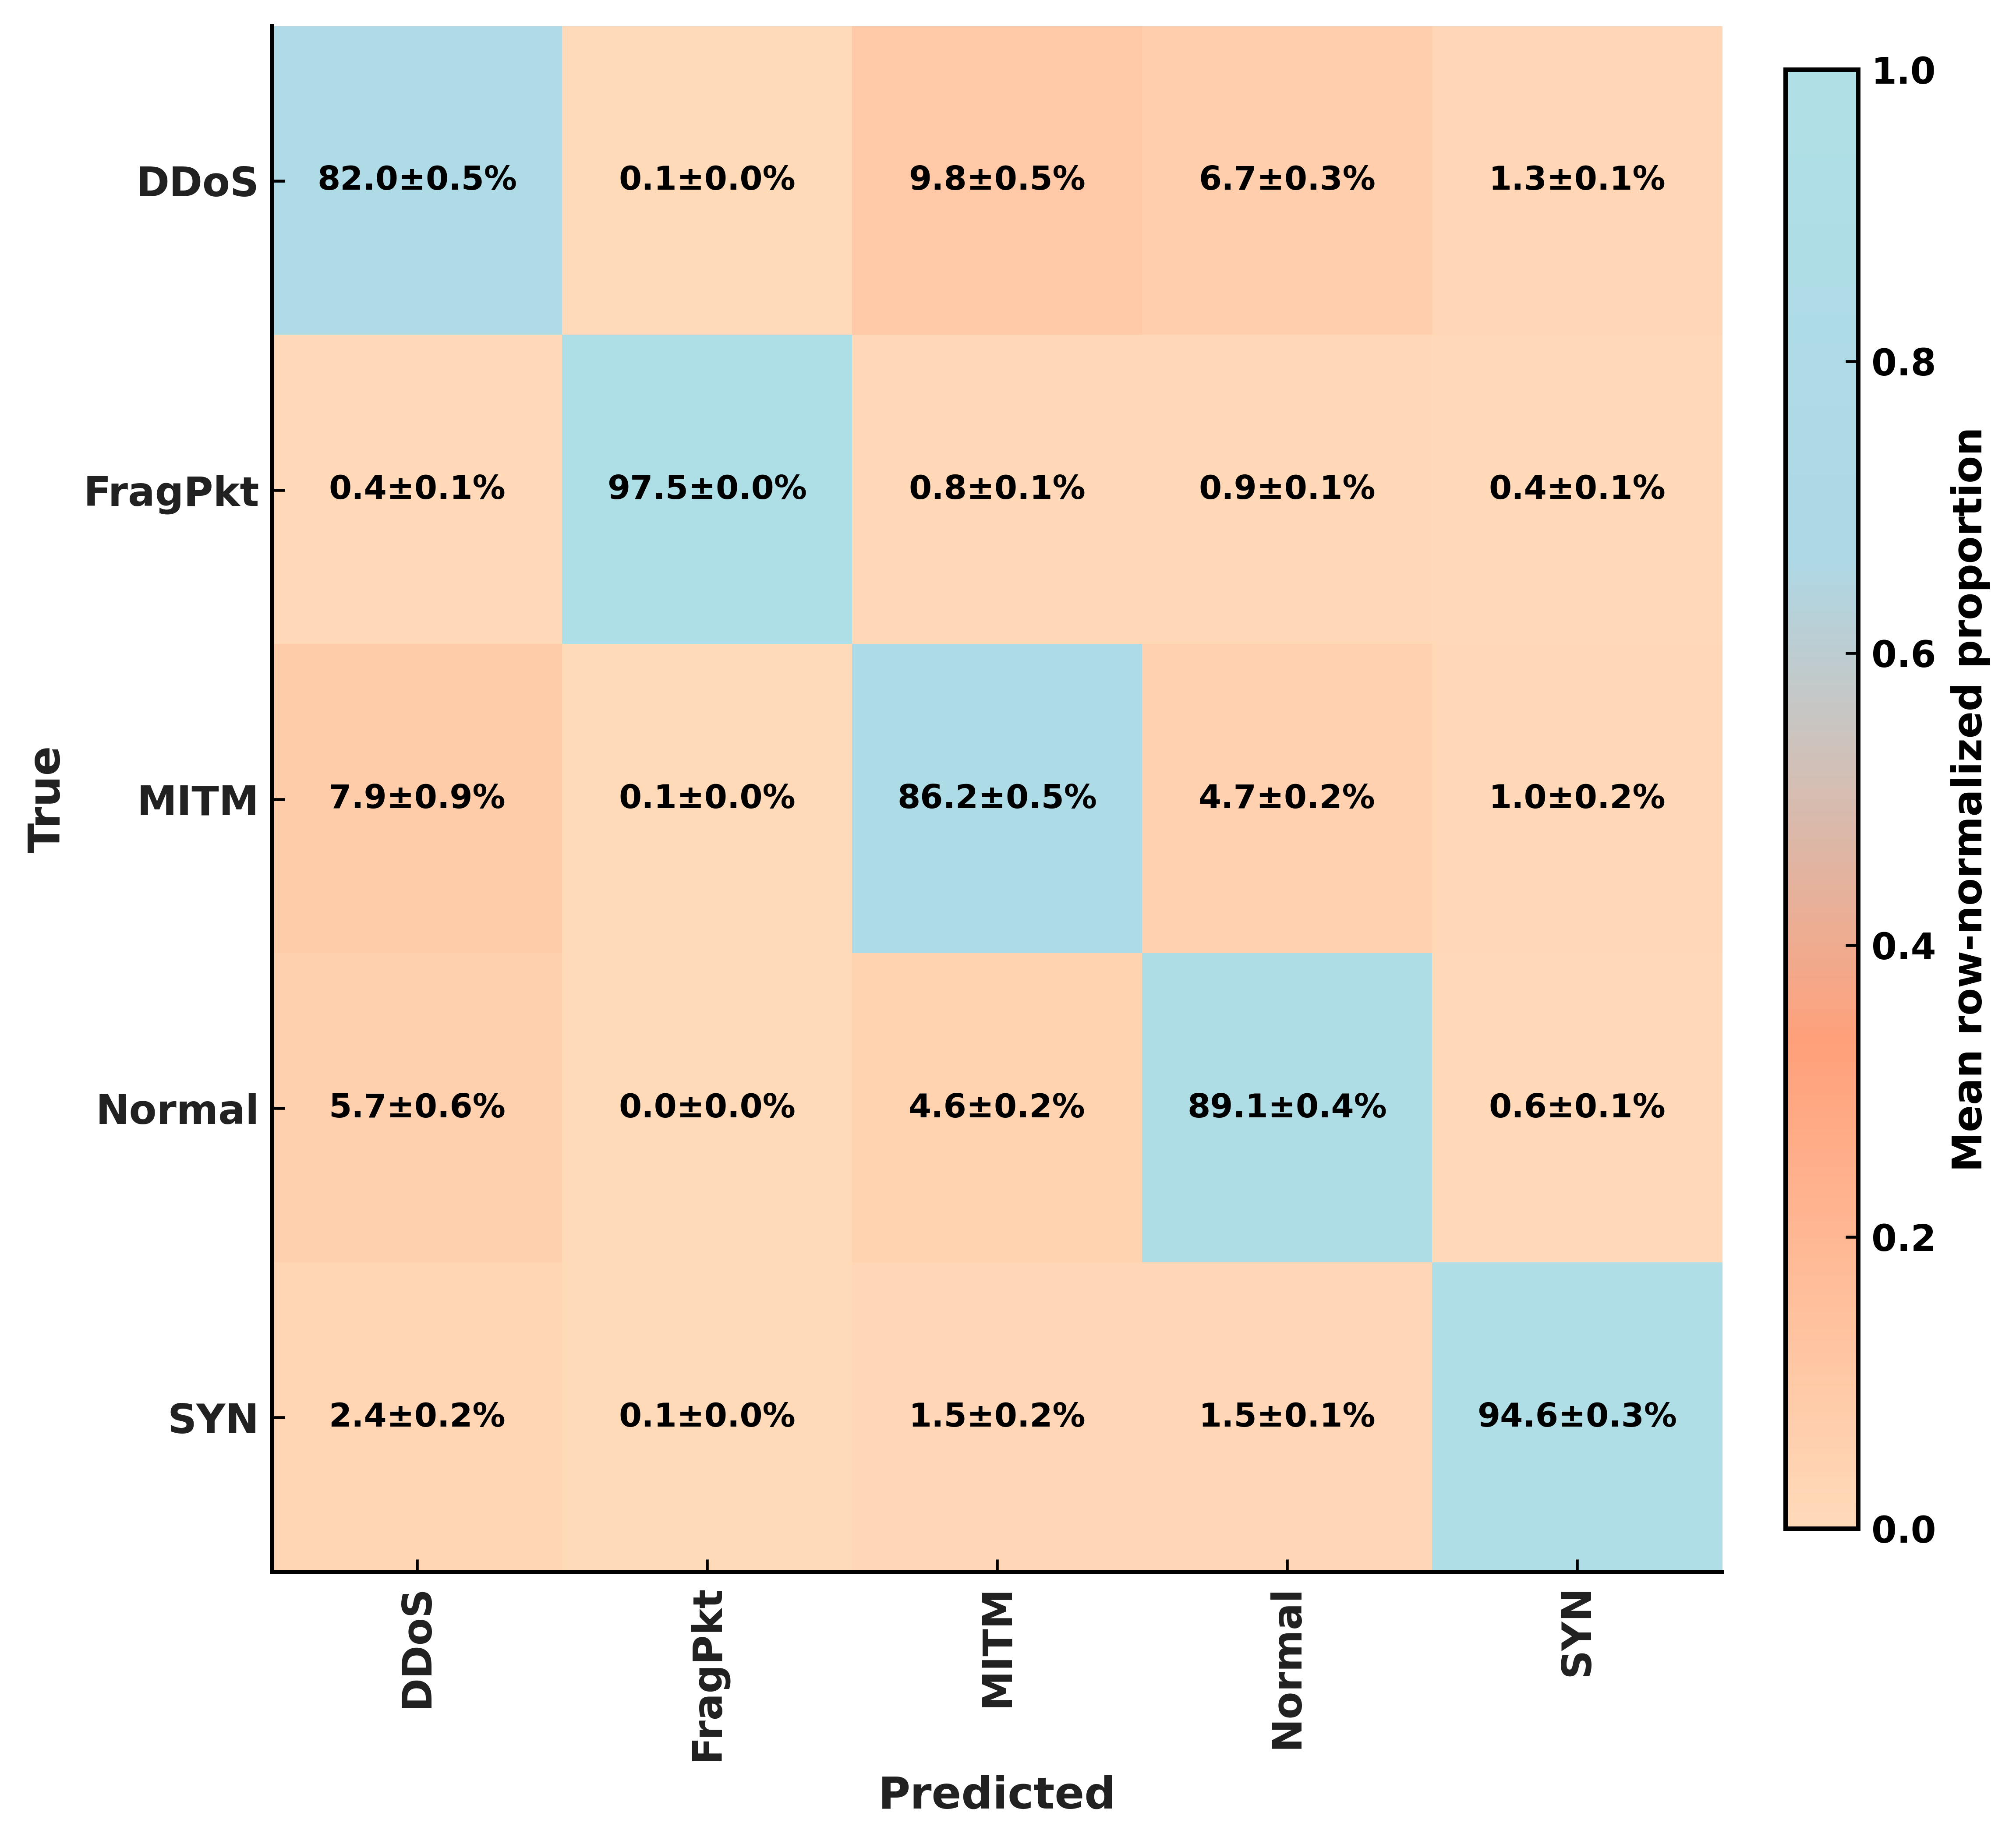

Saved PNG: FIVEQUBITS_reduced/figs/OD-IDS2022/QuantumTabNet/Q5/aggregate/confusion_matrix_test_agg_bold.png
Saved PDF: FIVEQUBITS_reduced/figs/OD-IDS2022/QuantumTabNet/Q5/aggregate/confusion_matrix_test_agg_bold.pdf
Saved EPS: FIVEQUBITS_reduced/figs/OD-IDS2022/QuantumTabNet/Q5/aggregate/confusion_matrix_test_agg_bold.eps


In [ ]:
# === Cell 4: Confusion Matrix aggregate (row-normalized; contrast cmap) =======
assert 'RES_DIR' in globals(), "Run Cell 0 first."
import numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from matplotlib.colors import LinearSegmentedColormap
import pandas as pd

dataset, model, qubits = "OD-IDS2022", "QuantumTabNet", 5
seed_root = PRED_DIR / dataset / model / f"Q{qubits}"
seed_dirs = sorted(
    [p for p in seed_root.glob("seed_*") if (p / "preds_test.csv").exists()],
    key=lambda p: int(p.name.split("_")[1])
)
SEEDS = [int(p.name.split("_")[1]) for p in seed_dirs]
seed_preds = {s: pd.read_csv(seed_root / f"seed_{s}" / "preds_test.csv") for s in SEEDS}
prob_cols   = [c for c in seed_preds[SEEDS[0]].columns if c.startswith("p_")]
class_names = [c.replace("p_", "") for c in prob_cols]
y_true      = seed_preds[SEEDS[0]]["y_true"].to_numpy()

C   = len(class_names)
cms = []
for s in SEEDS:
    P = seed_preds[s][prob_cols].to_numpy(float)
    y_pred = P.argmax(axis=1)
    cm = confusion_matrix(y_true, y_pred, labels=list(range(C)))
    cmn = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
    cms.append(cmn)
cms      = np.stack(cms, axis=0)
mean_cmn = cms.mean(axis=0)
std_cmn  = cms.std(axis=0)

contrast_cmap = LinearSegmentedColormap.from_list(
    "contrast", ["#FFDAB9", "#FFA07A", "#ADD8E6", "#B0E0E6"]
)

rc = {
    "figure.dpi": 600,
    "savefig.dpi": 600,
    "font.size": 11,
    "font.weight": "bold",
    "axes.labelsize": 12,
    "axes.labelweight": "bold",
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "axes.linewidth": 1.2,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "axes.facecolor": "none",
    "figure.facecolor": "none"
}

with plt.rc_context(rc):
    fig = plt.figure(figsize=(7.8, 7.2))
    ax  = fig.add_subplot(111)

    im = ax.imshow(
        mean_cmn,
        aspect="auto",
        interpolation="nearest",
        cmap=contrast_cmap,
        vmin=0,
        vmax=1
    )

    # Axis labels
    ax.set_xlabel("Predicted", color=PALETTE["annot"], fontsize=12, fontweight="bold")
    ax.set_ylabel("True",      color=PALETTE["annot"], fontsize=12, fontweight="bold")

    ax.set_xticks(range(C))
    ax.set_yticks(range(C))

    ax.set_xticklabels(
        class_names,
        rotation=90,
        color=PALETTE["annot"],
        fontsize=11,
        fontweight="bold"
    )
    ax.set_yticklabels(
        class_names,
        color=PALETTE["annot"],
        fontsize=11,
        fontweight="bold"
    )

    # Cell values
    for i in range(C):
        for j in range(C):
            m = mean_cmn[i, j] * 100.0
            s = std_cmn[i, j] * 100.0
            txt = f"{m:.1f}±{s:.1f}%"
            ax.text(
                j, i, txt,
                ha="center", va="center",
                color="black",
                fontsize=9,
                fontweight="bold"
            )

    # Colorbar
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label(
        "Mean row-normalized proportion",
        fontsize=11,
        fontweight="bold"
    )
    for t in cbar.ax.get_yticklabels():
        t.set_fontweight("bold")
        t.set_fontsize(10)

    # Save outputs
    out = fig_stem(dataset, model, qubits, "aggregate", "confusion_matrix_test_agg_bold")

    savefig_both(
        fig,
        out,
        {
            "dataset": dataset,
            "model": model,
            "qubits": qubits,
            "seed_or_tag": "aggregate",
            "plot_type": "confusion_agg_bold"
        }
    )

    # Additional PDF and EPS saving
    fig.savefig(out.with_suffix(".pdf"), dpi=600, bbox_inches="tight")
    fig.savefig(out.with_suffix(".eps"), format="eps", bbox_inches="tight")

    print("Saved PNG:", out.with_suffix(".png"))
    print("Saved PDF:", out.with_suffix(".pdf"))
    print("Saved EPS:", out.with_suffix(".eps"))


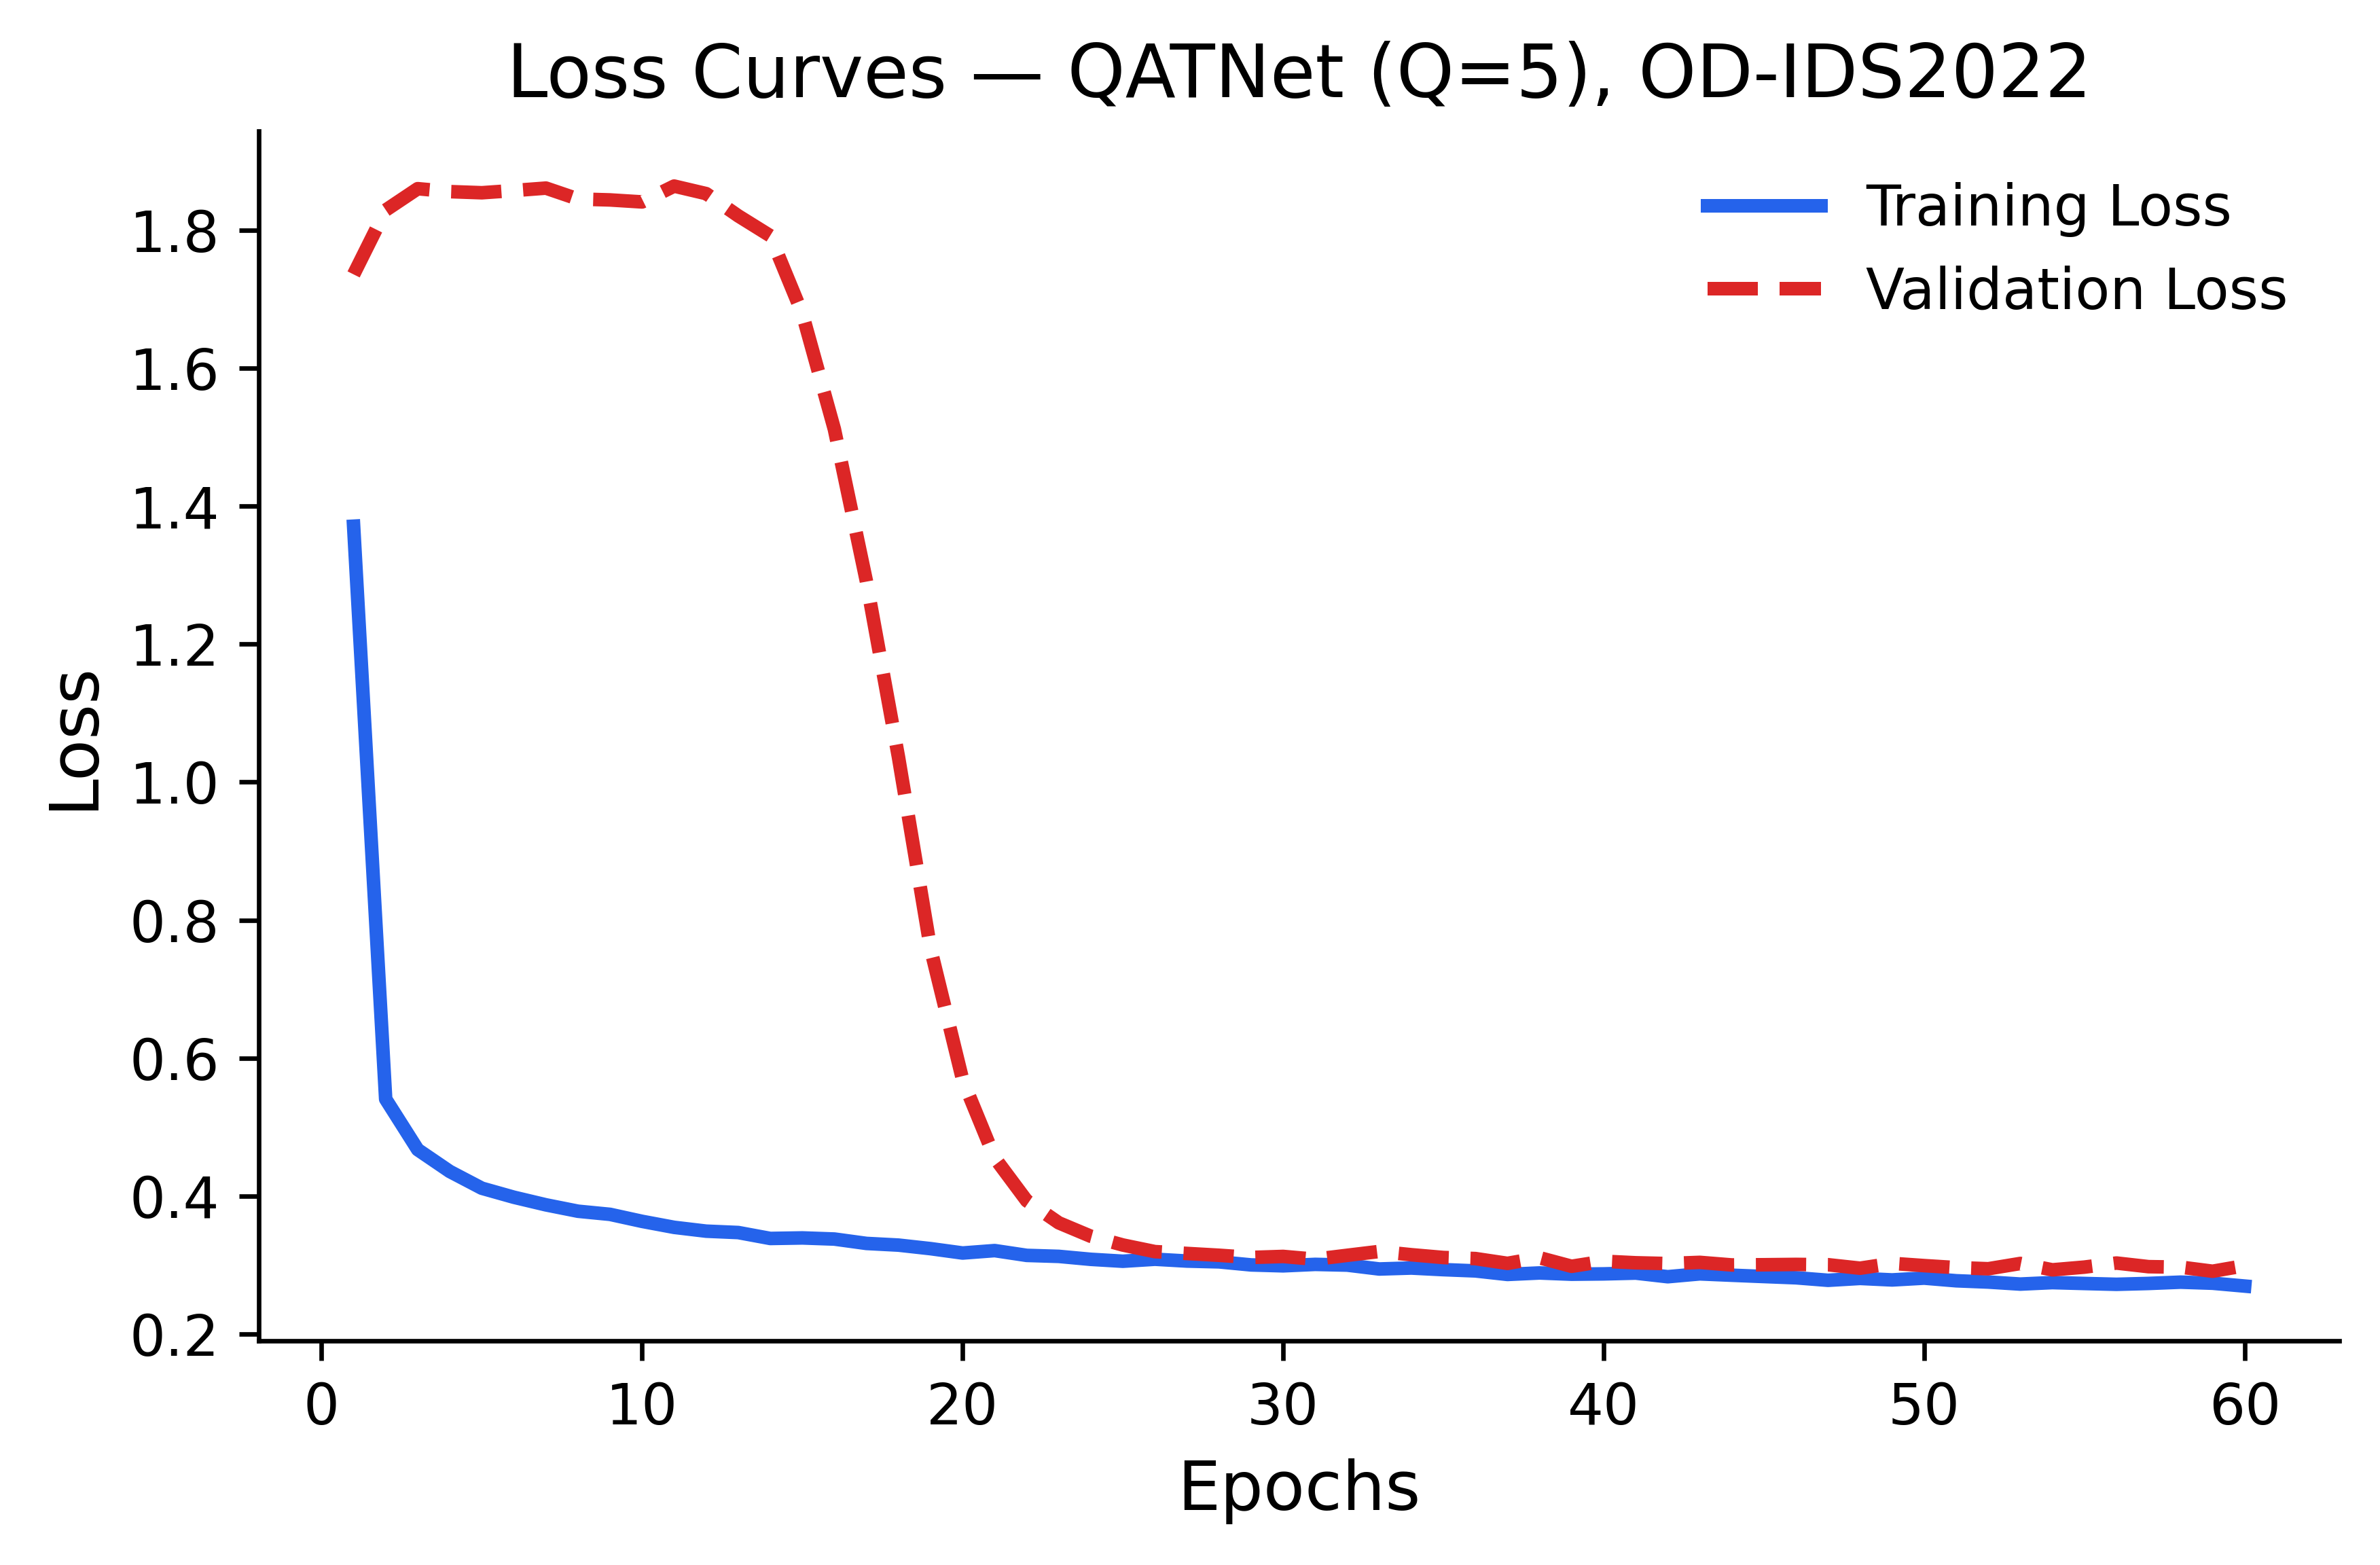

Saved: FIVEQUBITS_reduced/figs/OD-IDS2022/QuantumTabNet/Q5/seed_101/loss_curve_pub.png


In [ ]:
# === Cell:  Loss Curve (True Transparent, No Grid)
import numpy as np, pandas as pd, matplotlib.pyplot as plt

DATASET, MODEL, Q, SEED = "OD-IDS2022", "QuantumTabNet", 5, 101
TRAIN_COLOR, VAL_COLOR = "#2563eb", "#dc2626"  # blue/red palette

# ---- Load and clean ----
hist_dir = RES_DIR / "training_history" / DATASET / MODEL / f"Q{Q}"
csv_path = hist_dir / f"history_seed_{SEED}.csv"
H = pd.read_csv(csv_path)

# Normalize column names
H.columns = [c.lower().strip().replace(" ", "_") for c in H.columns]
H.rename(columns={
    "validation_loss": "val_loss", "valid_loss": "val_loss",
    "train_logloss": "train_loss"
}, inplace=True)

def numify(df, col):
    """Extract numeric values safely from a column."""
    if col not in df.columns:
        return None
    s = df[col].astype(str).str.extract(r"([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)")[0]
    return pd.to_numeric(s, errors="coerce").to_numpy()

# Extract values
E = numify(H, "epoch")
if E is None or len(E) == 0:
    E = np.arange(len(H))
trL = numify(H, "train_loss")
vaL = numify(H, "val_loss")

# ---- Plot ----
fig, ax = plt.subplots(figsize=(6, 4), dpi=600)

if trL is not None and len(trL) > 0:
    ax.plot(E, trL, color=TRAIN_COLOR, lw=2.4, label="Training Loss")
if vaL is not None and len(vaL) > 0:
    ax.plot(E, vaL, "--", color=VAL_COLOR, lw=2.4, label="Validation Loss")

ax.set_xlabel("Epochs", fontsize=12)
ax.set_ylabel("Loss", fontsize=12)
ax.set_title(f"Loss Curves — QATNet (Q={Q}), {DATASET}", fontsize=13)
ax.legend(frameon=False, fontsize=10)
ax.tick_params(axis='both', which='major', labelsize=10)

# ---- Keep axes, remove clutter ----
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.set_facecolor((0, 0, 0, 0))  # fully transparent axes background
fig.patch.set_facecolor((0, 0, 0, 0))  # fully transparent figure background
ax.grid(False)  # remove grid

plt.tight_layout()

# ---- Save & Show ----
out = fig_stem(DATASET, MODEL, Q, f"seed_{SEED}", "loss_curve_pub")
plt.savefig(out.with_suffix(".png"), dpi=600, transparent=True, bbox_inches="tight", pad_inches=0)
plt.show()

print("Saved:", out.with_suffix(".png"))


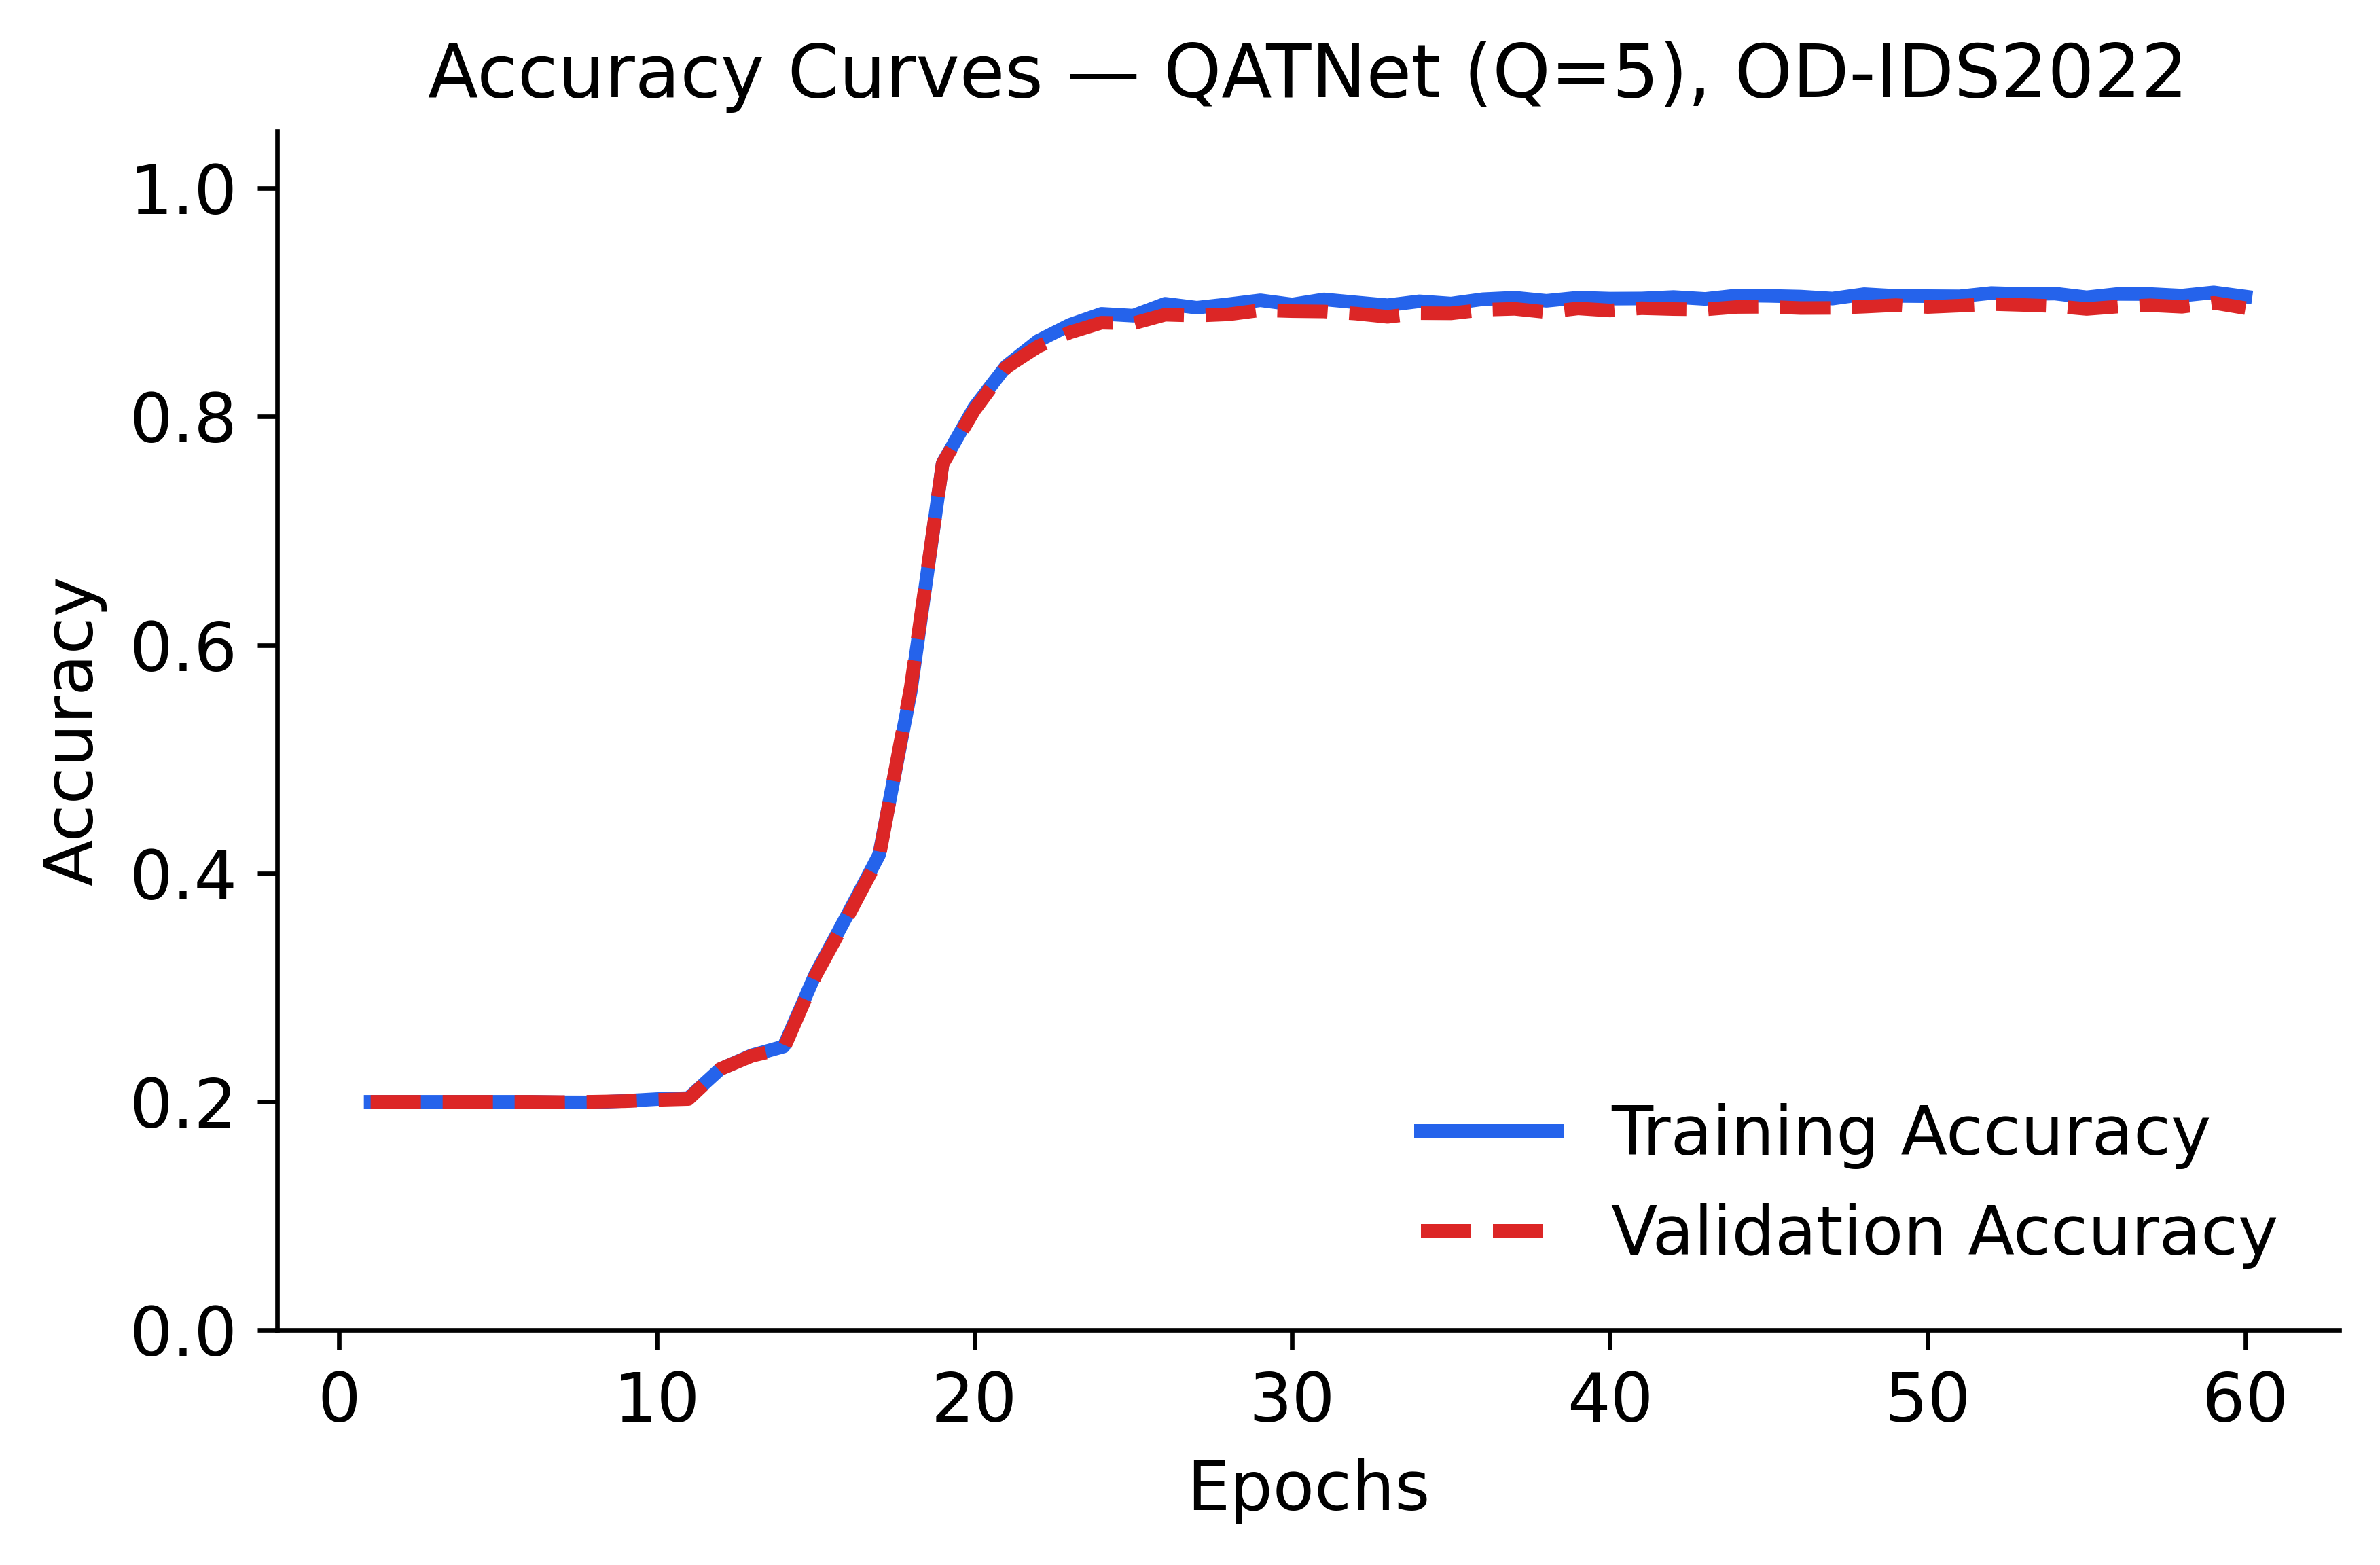

Saved: FIVEQUBITS_reduced/figs/OD-IDS2022/QuantumTabNet/Q5/seed_101/accuracy_curve_pub.png


In [ ]:
# === Transparent Accuracy Curve ===
import numpy as np, pandas as pd, matplotlib.pyplot as plt

DATASET, MODEL, Q, SEED = "OD-IDS2022", "QuantumTabNet", 5, 101
TRAIN_COLOR, VAL_COLOR = "#2563eb", "#dc2626"

hist_dir = RES_DIR / "training_history" / DATASET / MODEL / f"Q{Q}"
csv_path = hist_dir / f"history_seed_{SEED}.csv"
H = pd.read_csv(csv_path)

H.columns = [c.lower().strip().replace(" ", "_") for c in H.columns]
H.rename(columns={
    "validation_accuracy": "val_acc", "valid_accuracy": "val_acc",
    "train_accuracy": "train_acc"
}, inplace=True)

def numify(df, col):
    """Extract numeric values safely from a column."""
    if col not in df.columns:
        return None
    s = df[col].astype(str).str.extract(r"([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)")[0]
    return pd.to_numeric(s, errors="coerce").to_numpy()

E = numify(H, "epoch")
if E is None or len(E) == 0:
    E = np.arange(len(H))
trA = numify(H, "train_acc")
vaA = numify(H, "val_acc")

# ---- Plot ----
fig, ax = plt.subplots(figsize=(6, 4), dpi=600)

if trA is not None and len(trA) > 0:
    ax.plot(E, trA, color=TRAIN_COLOR, lw=2.4, label="Training Accuracy")
if vaA is not None and len(vaA) > 0:
    ax.plot(E, vaA, "--", color=VAL_COLOR, lw=2.4, label="Validation Accuracy")

ax.set_xlabel("Epochs", fontsize=12)
ax.set_ylabel("Accuracy", fontsize=12)
ax.set_title(f"Accuracy Curves — QATNet (Q={Q}), {DATASET}", fontsize=13)
ax.set_ylim(0, 1.05)
ax.legend(frameon=False)
ax.set_facecolor("none")      # transparent axes
fig.patch.set_alpha(0.0)      # transparent figure
ax.grid(False)                 # remove grid

plt.tight_layout()

# Save the figure
out = fig_stem(DATASET, MODEL, Q, f"seed_{SEED}", "accuracy_curve_pub")
fig.savefig(out.with_suffix(".png"), transparent=True, bbox_inches="tight", pad_inches=0)

# Show it in the console
plt.show()

plt.close(fig)
print("Saved:", out.with_suffix(".png"))


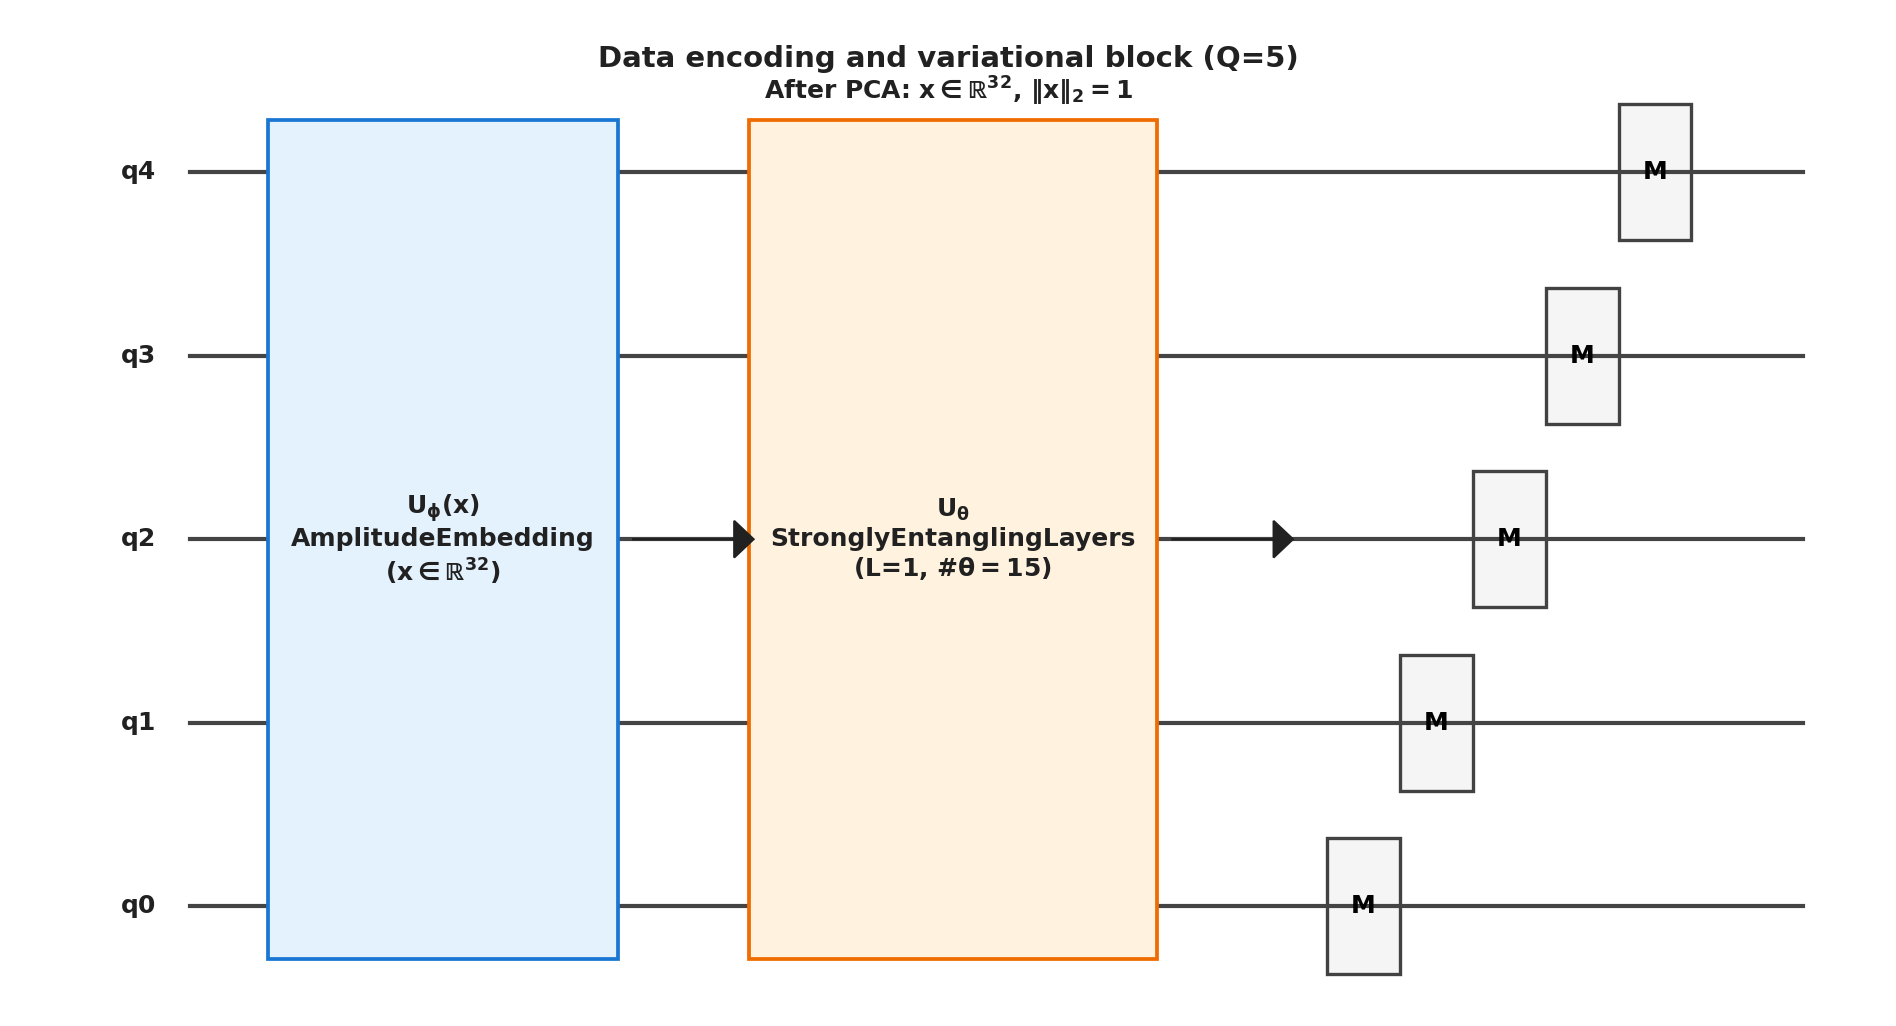

FIVEQUBITS_reduced/figs/circuits/Q5/panel_a_vqc_pipeline_Q5.png


In [ ]:
# === Cell 6: Circuit Panel (a) for Q=5 ==================
assert 'RES_DIR' in globals() and 'FIG_DIR' in globals() and 'PALETTE' in globals(), "Run Cell 0 first."
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrow
from matplotlib.lines import Line2D
import importlib as _imp
csv = _imp.import_module("csv")

dataset, model, qubits, L = "OD-IDS2022", "QuantumTabNet", 5, 1
TARGET_DIM = 2**qubits  # -> 32
cir_dir = FIG_DIR / "circuits" / f"Q{qubits}"; cir_dir.mkdir(parents=True, exist_ok=True)

fig = plt.figure(figsize=(12.8, 7.0))
ax = fig.add_subplot(111)
ax.axis("off")
ax.set_xlim(-1.2, 18.0)

# How far to move the whole diagram vertically (negative = down)
YSHIFT = -0.35

# ----- WIRES: 5 lines for Q=5 -----
ys0 = [3.2, 2.5, 1.8, 1.1, 0.4]     # 5 rows (q4..q0 top→bottom)
ys  = [y + YSHIFT for y in ys0]
ax.set_ylim(min(ys)-0.4, max(ys)+0.6)

def wire(y): ax.add_line(Line2D([0.6, 17.2], [y, y], lw=2, color=PALETTE["wire"]))
for y in ys: wire(y)
for i, y in enumerate(ys[::-1]):   # labels q0..q4 bottom→top
    ax.text(0.25, y, f"q{i}", va="center", ha="right", color=PALETTE["annot"])

y_mid = (ys[0] + ys[-1]) / 2.0

# ----- headings (use axes fraction so they don't shift) -----
ax.text(0.5, 0.97, f"Data encoding and variational block (Q={qubits})",
        transform=ax.transAxes, ha="center", va="top",
        fontsize=14, fontweight="bold", color=PALETTE["annot"])
ax.text(0.5, 0.94, rf"After PCA: $x\in\mathbb{{R}}^{{{TARGET_DIM}}}$, $\|x\|_2=1$",
        transform=ax.transAxes, ha="center", va="top", color=PALETTE["annot"])

def block(x, y0, y1, label, width, fc, ec):
    ax.add_patch(Rectangle((x, y0), width, y1 - y0, ec=ec, fc=fc, lw=1.8, zorder=2))
    ax.text(x + width/2, (y0 + y1)/2, label, ha="center", va="center", color=PALETTE["annot"])
    return x + width

def arrow(x0, y, dx):
    ax.add_patch(FancyArrow(x0, y, dx, 0,
                            width=0.0, head_width=0.14, head_length=0.2,
                            length_includes_head=True, color=PALETTE["annot"], zorder=3))

def measure(x, y):
    w, h = 0.75, 0.52
    ax.add_patch(Rectangle((x, y - h/2), w, h, ec=PALETTE["measure_edge"], fc="#f5f5f5", lw=1.6))
    ax.text(x + w/2, y, "M", ha="center", va="center")
    return x + w

x = 1.4
y0, y1 = min(ys) - 0.2, max(ys) + 0.2

x = block(
    x, y0, y1,
    rf"$U_\phi(x)$" + "\nAmplitudeEmbedding\n" + rf"($x\in\mathbb{{R}}^{{{TARGET_DIM}}}$)",
    width=3.6, fc=PALETTE["amp_fill"], ec=PALETTE["amp_edge"]
)
arrow(x + 0.15, y_mid, 1.25); x += 1.35

x = block(
    x, y0, y1,
    rf"$U_\theta$" + "\nStronglyEntanglingLayers\n" + rf"(L={L}, $\#\theta={3*qubits*L}$)",
    width=4.2, fc=PALETTE["vqc_fill"], ec=PALETTE["vqc_edge"]
)
arrow(x + 0.15, y_mid, 1.25); x += 1.40

mx = x + 0.35
for y in ys[::-1]:   # 5 measurement boxes
    mx = measure(mx, y)

out = cir_dir / f"panel_a_vqc_pipeline_Q{qubits}"
savefig_both(fig, out, {"dataset":dataset,"model":model,"qubits":qubits,
                        "seed_or_tag":"circuits","plot_type":"circuit_panel_a"})
print(out.with_suffix(".png"))


In [ ]:
# === Cell 7: Circuit Panel (b) for Q=5 
assert 'RES_DIR' in globals() and 'FIG_DIR' in globals() and 'PALETTE' in globals(), "Run Cell 0 first."
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrow, Circle
from matplotlib.lines import Line2D
import matplotlib as mpl
import importlib as _imp
csv = _imp.import_module("csv")

# ---------- Global bold settings ----------
mpl.rcParams.update({
    "font.weight": "bold",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "mathtext.default": "bf",   # bold math
})

dataset, model, qubits, L = "OD-IDS2022", "QuantumTabNet", 5, 1
cir_dir = FIG_DIR / "circuits" / f"Q{qubits}"; cir_dir.mkdir(parents=True, exist_ok=True)

# -------- canvas --------
fig = plt.figure(figsize=(12.8, 7.0))
ax = fig.add_subplot(111); ax.axis("off")
ax.set_xlim(-0.8, 18.0)

# vertical shift
YSHIFT = -0.55

# ----- WIRES: 5 lines for Q=5 (q4..q0 top→bottom) -----
ys0 = [3.2, 2.5, 1.8, 1.1, 0.4]
ys  = [y + YSHIFT for y in ys0]
ax.set_ylim(min(ys) - 0.4, max(ys) + 0.6)

for y in ys:
    ax.add_line(Line2D([0.6, 17.2], [y, y], lw=2, color=PALETTE["wire"]))
for i, y in enumerate(ys[::-1]):  # labels q0..q4
    ax.text(0.25, y, f"q{i}", va="center", ha="right",
            color=PALETTE["annot"], fontweight="bold", fontsize=11)

y_mid = (ys[0] + ys[-1]) / 2.0

# -------- headings (bold) --------
ax.text(0.5, 0.97, "One layer of StronglyEntanglingLayers",
        transform=ax.transAxes, ha="center", va="top",
        fontsize=14, fontweight="bold", color=PALETTE["annot"])
ax.text(0.5, 0.94,
        r"Per qubit: $\mathbf{R_x}(\boldsymbol{\theta}_{l,q,0})\,\mathbf{R_y}(\boldsymbol{\theta}_{l,q,1})\,\mathbf{R_z}(\boldsymbol{\theta}_{l,q,2})$ + ring CNOTs",
        transform=ax.transAxes, ha="center", va="top",
        color=PALETTE["annot"], fontweight="bold")

# -------- helpers --------
def block(ax, x, y0, y1, text, width=1.6, fc="#fff", ec="#000", lw=1.8):
    ax.add_patch(Rectangle((x, y0), width, y1-y0, ec=ec, fc=fc, lw=lw, zorder=2))
    ax.text(x+width/2, (y0+y1)/2, text, ha="center", va="center",
            color=PALETTE["annot"], fontweight="bold")
    return x+width

def rxryrz(ax, x, y, spacing=0.22):
    w, h = 0.34, 0.34
    for lab in (r"$\mathbf{R_x}$", r"$\mathbf{R_y}$", r"$\mathbf{R_z}$"):
        ax.add_patch(Rectangle((x, y-h/2), w, h,
                               ec=PALETTE["rot_edge"], fc=PALETTE["rot_fill"], lw=1.6, zorder=3))
        ax.text(x+w/2, y, lab, ha="center", va="center", fontsize=10,
                color=PALETTE["annot"], fontweight="bold")
        x += w + spacing
    ax.text(x-(3*w+2*spacing)/2, y+0.40, r"$\boldsymbol{\theta}_{l,q,\{0,1,2\}}$",
            ha="center", va="bottom", fontsize=10, fontweight="bold")
    return x

def cnot(ax, x, y_c, y_t):
    ax.add_line(Line2D([x, x], [y_c, y_t], lw=1.8, color=PALETTE["cnot_line"], zorder=1))
    ax.add_patch(Circle((x, y_c), 0.06, color=PALETTE["cnot_line"], zorder=3))
    r = 0.12
    ax.add_patch(Circle((x, y_t), r, ec=PALETTE["cnot_line"], fc="white", lw=1.8, zorder=3))
    ax.add_line(Line2D([x-r*0.7, x+r*0.7], [y_t, y_t], lw=1.5, color=PALETTE["cnot_line"], zorder=3))
    ax.add_line(Line2D([x, x], [y_t-r*0.7, y_t+r*0.7], lw=1.5, color=PALETTE["cnot_line"], zorder=3))

def measure(ax, x, y):
    w, h = 0.75, 0.52
    ax.add_patch(Rectangle((x, y-h/2), w, h, ec=PALETTE["measure_edge"], fc="#f5f5f5", lw=1.6))
    ax.text(x+w/2, y, "M", ha="center", va="center", fontweight="bold", fontsize=11)
    return x + w

# -------- blocks --------
x = 1.2
y0, y1 = min(ys) - 0.2, max(ys) + 0.2
x = block(ax, x, y0, y1, r"$\mathbf{U}_{\boldsymbol{\phi}}(x)$",
          width=1.6, fc=PALETTE["enc_fill"], ec=PALETTE["enc_edge"])
ax.add_patch(FancyArrow(x+0.12, y_mid, 0.9, 0, width=0.0, head_width=0.14, head_length=0.2,
                        length_includes_head=True, color=PALETTE["annot"], zorder=3))
x += 1.1

# per-qubit rotations for 5 qubits
ends = []
for y in ys[::-1]:
    ends.append(rxryrz(ax, x, y, spacing=0.22))
x_rot_end = max(ends)

# CNOT ring for 5 qubits: 0→1→2→3→4→0
cx = x_rot_end + 0.8
ymap = {i: y for i, y in enumerate(ys[::-1])}
for c, t in [(0,1), (1,2), (2,3), (3,4), (4,0)]:
    cnot(ax, cx, ymap[c], ymap[t])
    cx += 1.0

# measurements (5 boxes)
mx = cx + 1.0
for y in ys[::-1]:
    mx = measure(ax, mx, y)

# -------- save high-quality outputs --------
out = cir_dir / f"panel_b_strongly_entangling_layer_Q{qubits}"
savefig_both(fig, out, {"dataset":dataset,"model":model,"qubits":qubits,
                        "seed_or_tag":"circuits","plot_type":"circuit_panel_b"})
print(out.with_suffix(".png"))

# Also export vector (for journal-quality)
fig.savefig(str(out.with_suffix(".svg")), format="svg", dpi=600)
fig.savefig(str(out.with_suffix(".eps")), format="eps", dpi=600)


FIVEQUBITS_reduced/figs/circuits/Q5/panel_b_strongly_entangling_layer_Q5.png


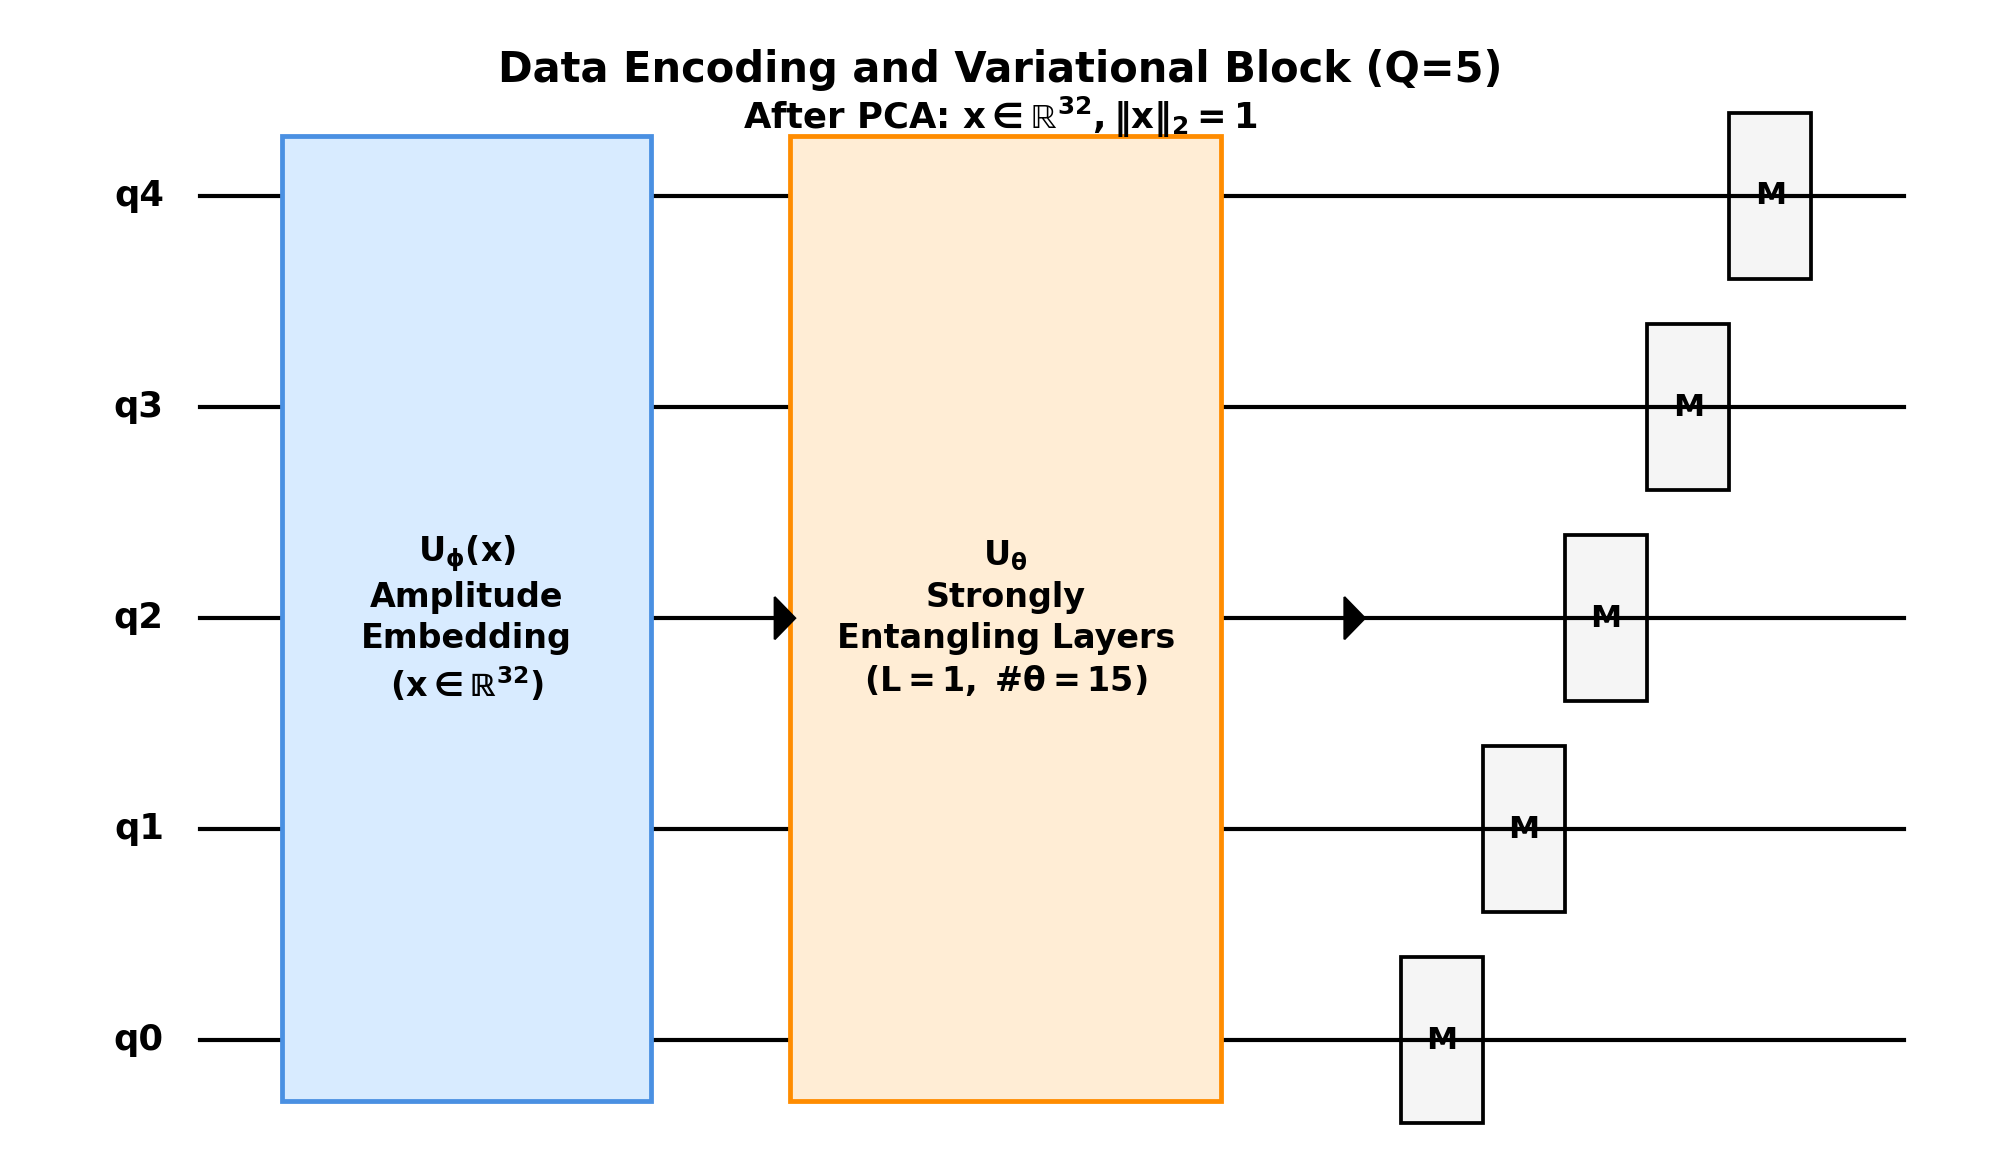

In [ ]:
# === Circuit Panel (a) for Q=5 — 
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrow
from matplotlib.lines import Line2D

dataset, model, qubits, L = "OD-IDS2022", "QuantumTabNet", 5, 1
TARGET_DIM = 2**qubits  # -> 32

fig = plt.figure(figsize=(13.5, 8.0))
ax = fig.add_subplot(111)
ax.axis("off")
ax.set_xlim(-1.2, 18.0)

YSHIFT = -0.35
ys0 = [3.2, 2.5, 1.8, 1.1, 0.4]
ys = [y + YSHIFT for y in ys0]
ax.set_ylim(min(ys)-0.4, max(ys)+0.6)

# Wires + labels
def wire(y): ax.add_line(Line2D([0.6, 17.2], [y, y], lw=2, color="black"))
for y in ys: wire(y)
for i, y in enumerate(ys[::-1]):
    ax.text(0.25, y, f"q{i}", va="center", ha="right",
            fontsize=17, fontweight="bold", color="black")

y_mid = (ys[0] + ys[-1]) / 2.0

# Headings (bold via fontweight; math symbols bold via \mathbf)
ax.text(0.5, 0.97,
        f"Data Encoding and Variational Block (Q={qubits})",
        transform=ax.transAxes, ha="center", va="top",
        fontsize=20, fontweight="bold", color="black")

ax.text(0.5, 0.93,
        rf"After PCA: $\mathbf{{x}}\in\mathbb{{R}}^{{{TARGET_DIM}}}, \|\mathbf{{x}}\|_2=1$",
        transform=ax.transAxes, ha="center", va="top",
        fontsize=17, fontweight="bold", color="black")

def block(x, y0, y1, label, width, fc, ec):
    ax.add_patch(Rectangle((x, y0), width, y1 - y0, ec=ec, fc=fc, lw=2.3, zorder=2))
    ax.text(x + width/2, (y0 + y1)/2, label,
            ha="center", va="center",
            fontsize=16, fontweight="bold", color="black",
            linespacing=1.3)
    return x + width

def arrow(x0, y, dx):
    ax.add_patch(FancyArrow(x0, y, dx, 0,
                            width=0.0, head_width=0.14, head_length=0.2,
                            length_includes_head=True, color="black", zorder=3))

def measure(x, y):
    w, h = 0.8, 0.55
    ax.add_patch(Rectangle((x, y - h/2), w, h, ec="black", fc="#f5f5f5", lw=1.8))
    ax.text(x + w/2, y, "M", ha="center", va="center",
            fontsize=15, fontweight="bold", color="black")
    return x + w

# --- Wrapped, bold labels (mathtext only; no \textbf) ---
amp_label = (
    r"$\mathbf{U_\phi(x)}$" + "\n"
    "Amplitude\n"
    "Embedding\n"
    rf"$\mathbf{{(x \in \mathbb{{R}}^{ {TARGET_DIM} })}}$"
)

vqc_label = (
    r"$\mathbf{U_\theta}$" + "\n"
    "Strongly\n"
    "Entangling Layers\n"
    rf"$\mathbf{{(L={L},\ \#\theta={3*qubits*L})}}$"
)

# Draw blocks
x = 1.4
y0, y1 = min(ys) - 0.2, max(ys) + 0.2

x = block(x, y0, y1, amp_label, width=3.6, fc="#d8ebff", ec="#4a90e2")
arrow(x + 0.15, y_mid, 1.25); x += 1.35

x = block(x, y0, y1, vqc_label, width=4.2, fc="#ffedd5", ec="#ff8c00")
arrow(x + 0.15, y_mid, 1.25); x += 1.40

mx = x + 0.35
for y in ys[::-1]:
    mx = measure(mx, y)

plt.tight_layout()
plt.savefig("panel_a_vqc_pipeline_Q5_bold.png", dpi=450, bbox_inches='tight')
plt.show()


/home/g202319370/.local/lib/python3.10/site-packages/pytorch_tabnet/abstract_model.py:82: UserWarning: Device used : cuda
  warnings.warn(f"Device used : {self.device}")
/home/g202319370/.local/lib/python3.10/site-packages/pytorch_tabnet/abstract_model.py:454: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where 

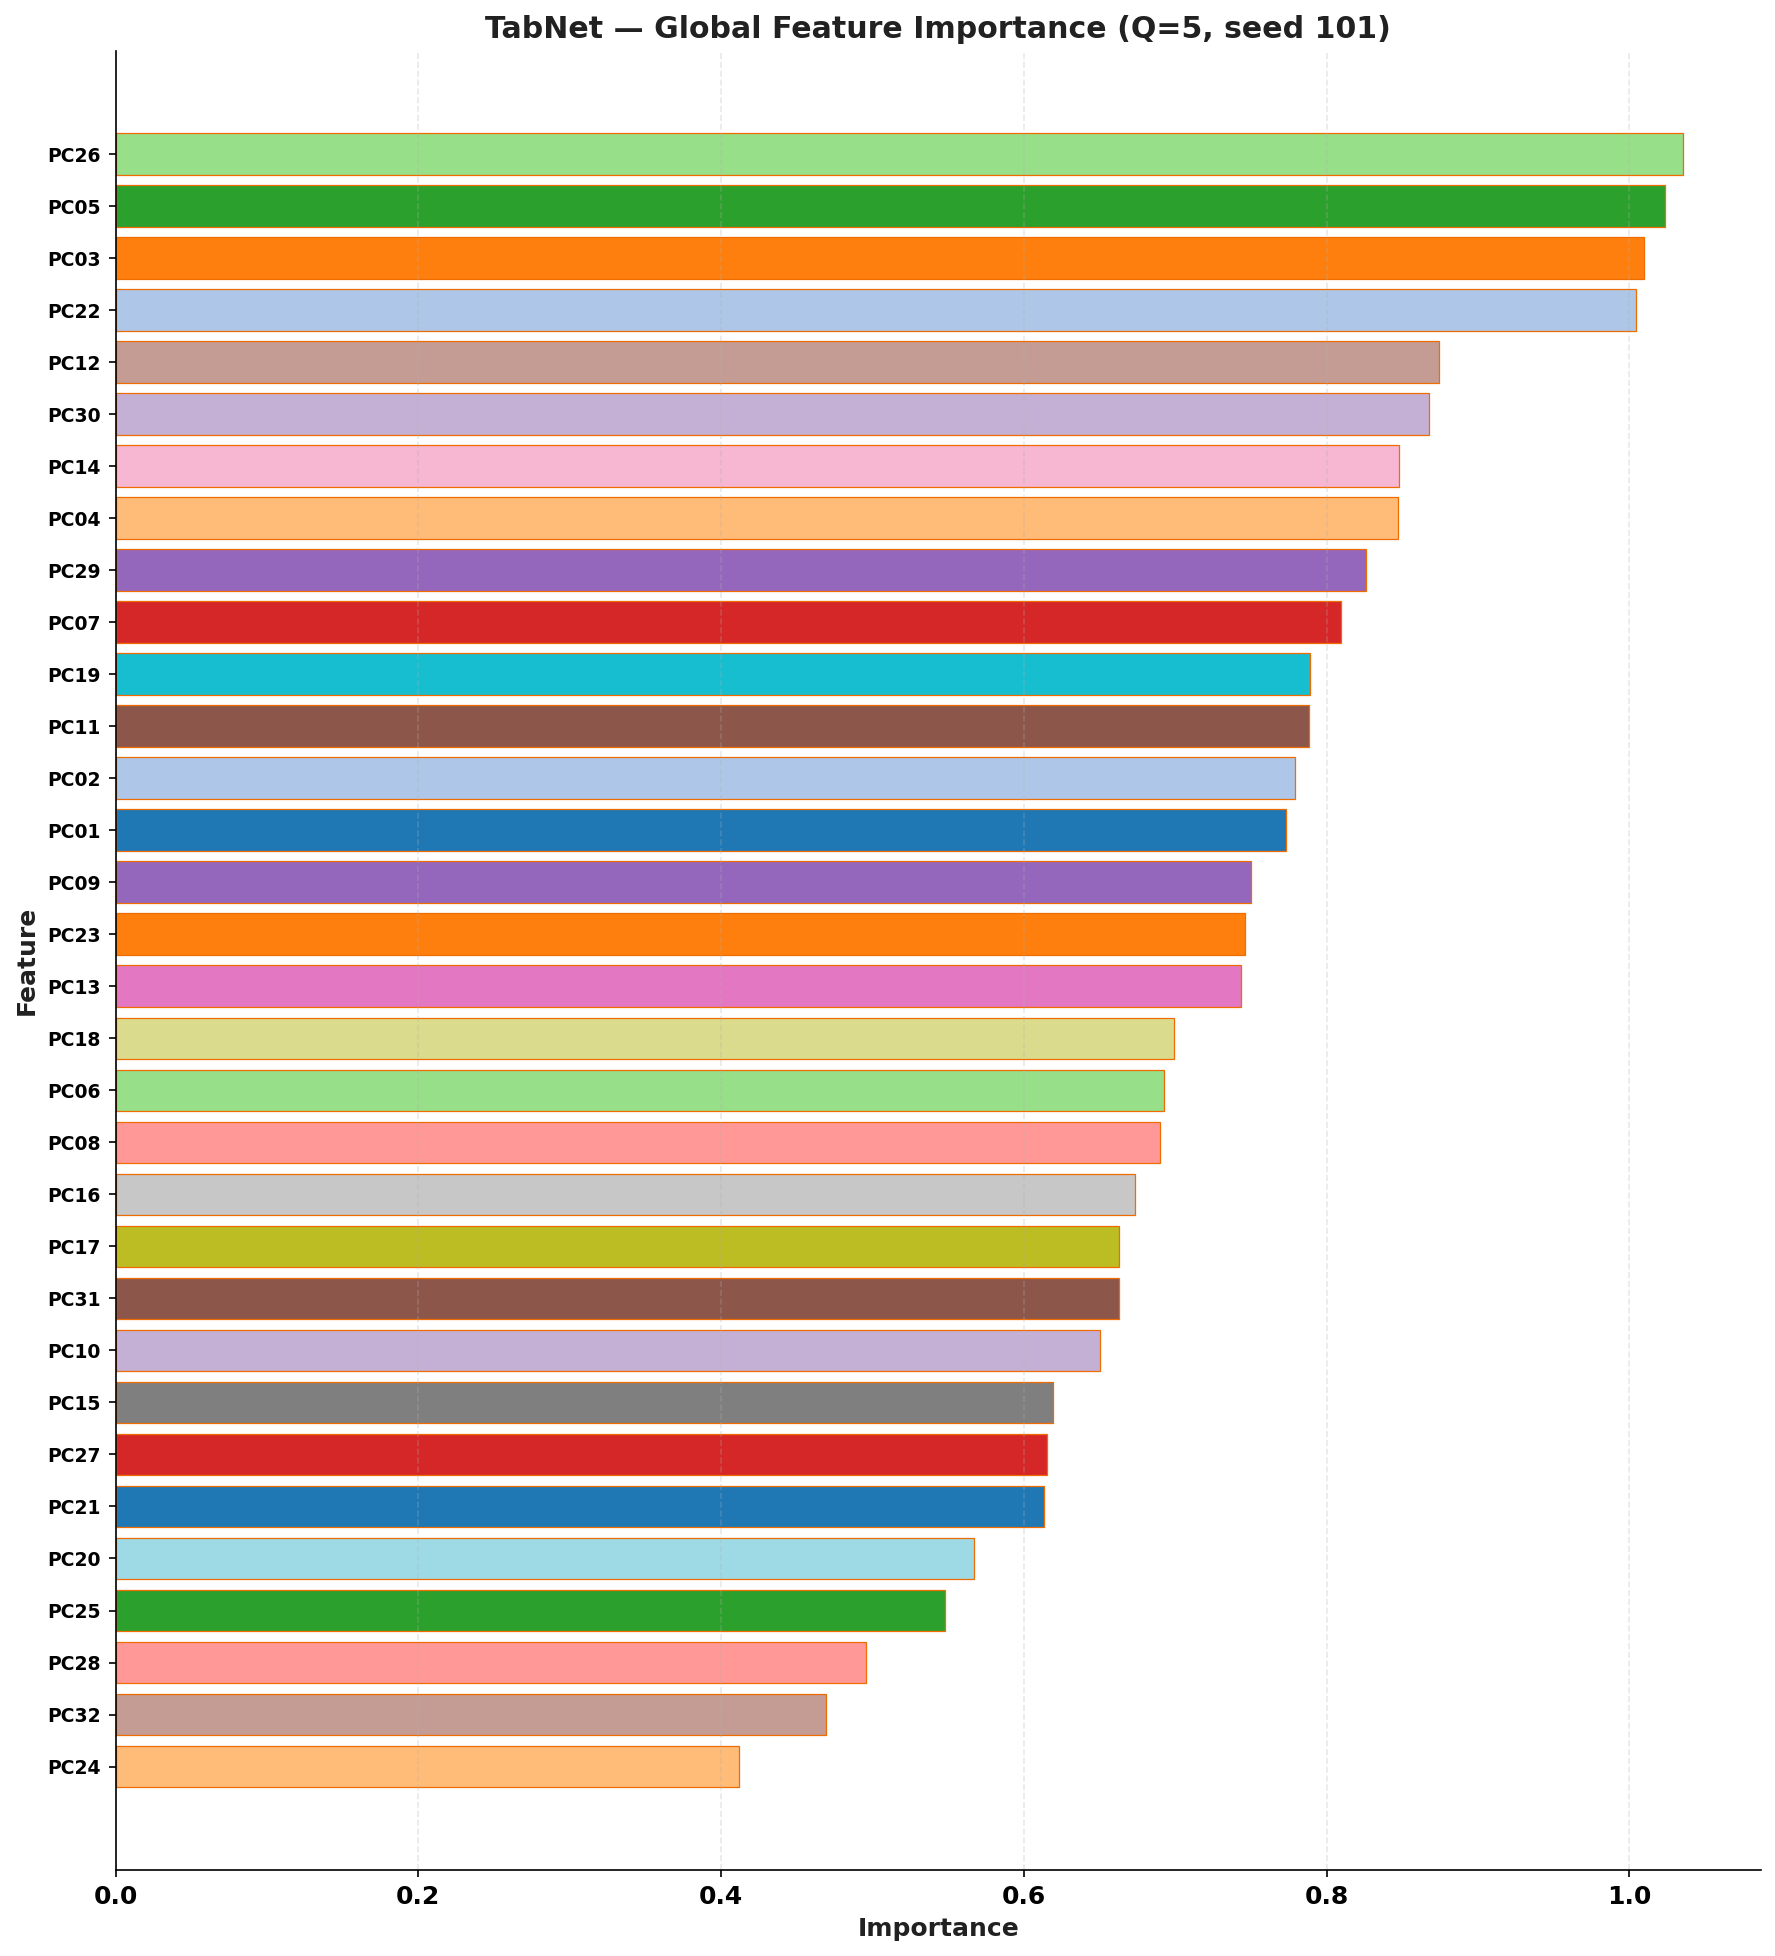

Saved: FIVEQUBITS_reduced/figs/OD-IDS2022/QuantumTabNet/Q5/seed_101/tabnet_global_feature_importance_colored_full.png


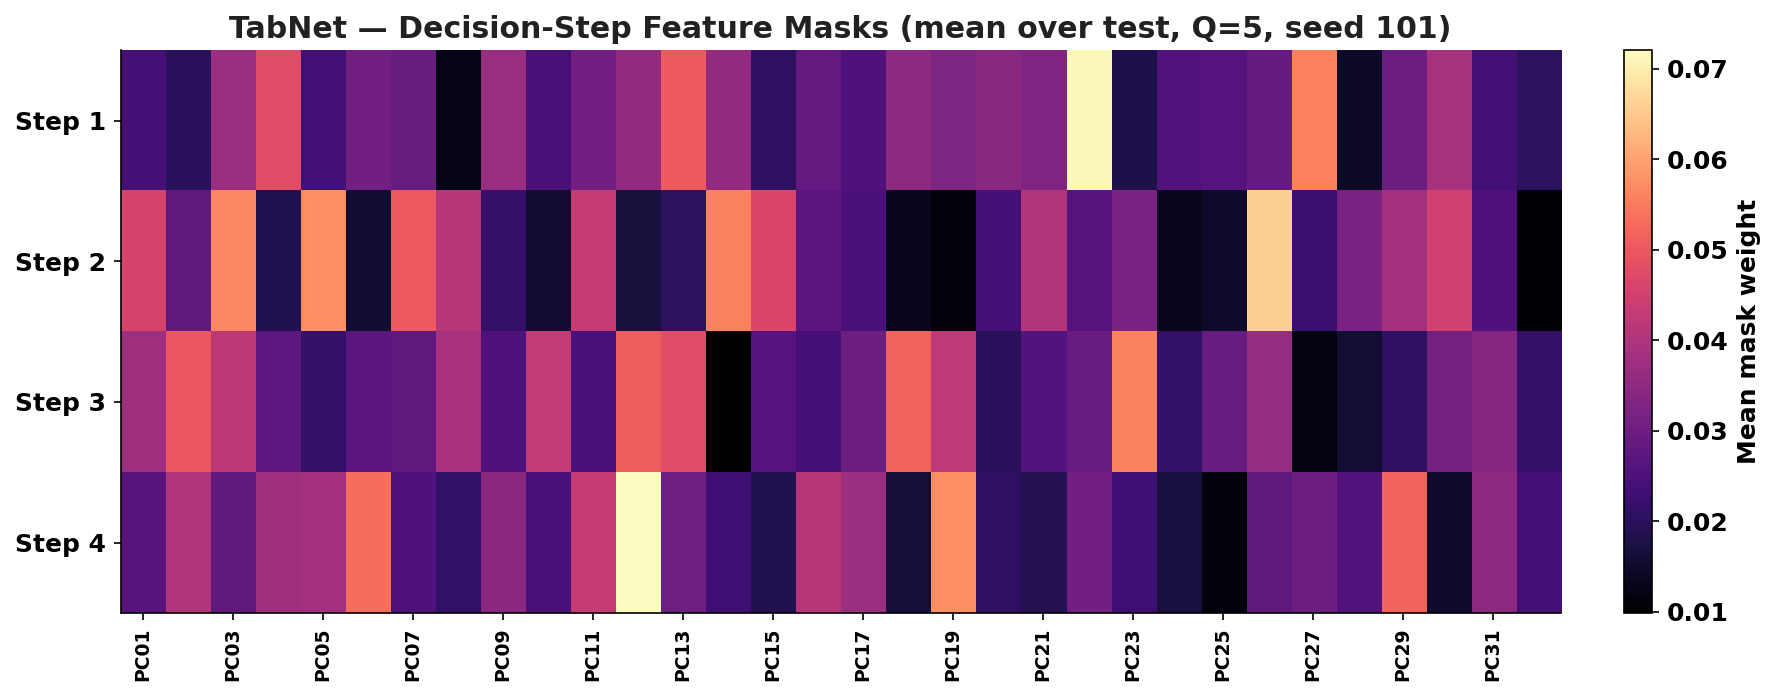

Saved: FIVEQUBITS_reduced/figs/OD-IDS2022/QuantumTabNet/Q5/seed_101/tabnet_masks_step_mean.png


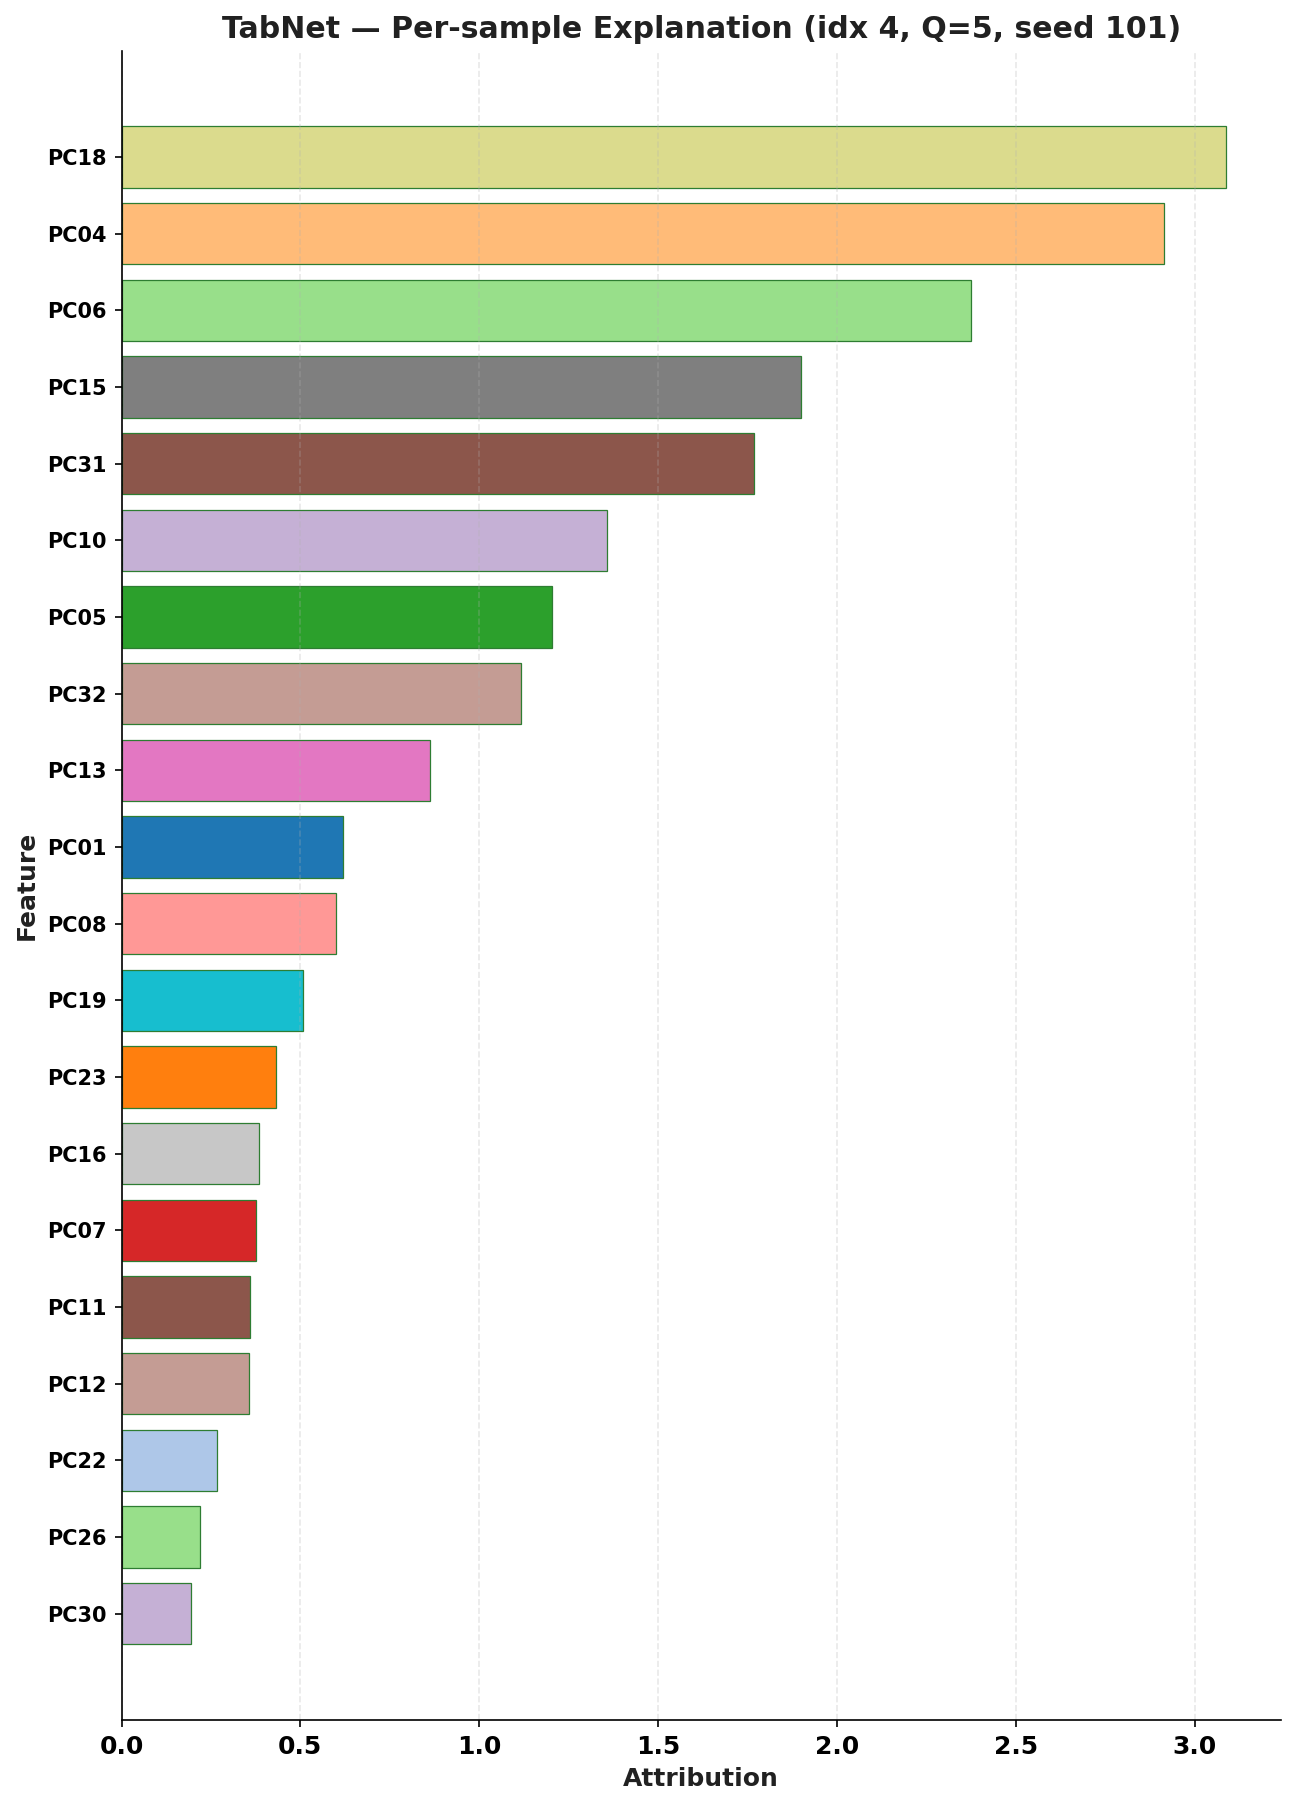

Saved: FIVEQUBITS_reduced/figs/OD-IDS2022/QuantumTabNet/Q5/seed_101/tabnet_explain_sample_4_colored_top20.png


In [ ]:
# === Cell 8 (3 plots only): FI(64) + Masks + Per-sample (Q=5, seed 101) ===
assert all(k in globals() for k in ["RES_DIR","PRED_DIR","preds_dir","fig_stem","savefig_both","PALETTE"]), "Run Cell 0 first."

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib import cm
from pytorch_tabnet.tab_model import TabNetClassifier

# ---------------------- config ----------------------
DATASET, MODEL, Q, SEED = "OD-IDS2022", "QuantumTabNet", 5, 101
TOPK = 20                  # used only for per-sample plot
GRID_ALPHA = 0.28
plt.rcParams["savefig.dpi"] = 300

# ---------------------- robust model load ----------------------
MODEL_DIR = RES_DIR / "models" / DATASET / MODEL / f"Q{Q}"
base = MODEL_DIR / f"tabnet_seed_{SEED}"
zip_path = base.with_suffix(".zip")
clf = TabNetClassifier()
if zip_path.exists(): clf.load_model(str(zip_path))
elif base.exists():   clf.load_model(str(base))
else: raise FileNotFoundError(f"Missing model: {zip_path} (or {base}). Re-run training cell.")

# ---------------------- data ----------------------
pdir   = preds_dir(DATASET, MODEL, Q, SEED)
X_te_q = np.load(pdir / "q_features_test.npy")
preds  = pd.read_csv(pdir / "preds_test.csv")
y_true = preds["y_true"].to_numpy()
prob_cols = [c for c in preds.columns if c.startswith("p_")]
P = preds[prob_cols].to_numpy(float)
y_pred = P.argmax(1)

# clearer names: PC01..PC64
n_features = X_te_q.shape[1]
feat_names = [f"PC{(i+1):02d}" for i in range(n_features)]
cmap = cm.get_cmap("tab20", 20)
COLORS = {feat_names[i]: cmap(i % 20) for i in range(n_features)}

# ---------------------- explain once ----------------------
M_explain, raw_masks = clf.explain(X_te_q)

def to_numpy(a):
    try:
        import torch
        if "Tensor" in type(a).__name__:
            return a.detach().cpu().numpy()
    except Exception:
        pass
    return np.asarray(a)

def normalize_masks(m):
    if isinstance(m, (list, tuple)): return [to_numpy(x) for x in m]
    if isinstance(m, dict):
        if "masks" in m and isinstance(m["masks"], (list, tuple)):
            return [to_numpy(x) for x in m["masks"]]
        if "attentive_masks" in m and isinstance(m["attentive_masks"], (list, tuple)):
            return [to_numpy(x) for x in m["attentive_masks"]]
        try:
            items = sorted(m.items(), key=lambda kv: kv[0])
            return [to_numpy(x) for _, x in items]
        except Exception:
            return [to_numpy(v) for v in m.values()]
    arr = to_numpy(m)
    return [arr] if arr.ndim == 2 else []

masks = normalize_masks(raw_masks)
if not masks:
    raise RuntimeError("No masks returned from TabNet.explain().")

# ================= 1) GLOBAL FEATURE IMPORTANCE (FULL 64 ONLY) ================
fi = getattr(clf, "feature_importances_", None)
if fi is None or (isinstance(fi, (list, np.ndarray)) and np.sum(fi) == 0):
    fi = to_numpy(M_explain).mean(axis=0)
fi = np.asarray(fi, float)
order = np.argsort(fi)[::-1]
fi_sorted = fi[order]
names_sorted = [feat_names[i] for i in order]
bar_colors = [COLORS[n] for n in names_sorted]

bar_height = 0.35
fig_h = min(30, 2.0 + bar_height * len(names_sorted))
fig = plt.figure(figsize=(12, fig_h))
ax = fig.add_subplot(111)
ax.barh(names_sorted[::-1], fi_sorted[::-1],
        color=bar_colors[::-1], edgecolor=PALETTE["vqc_edge"], linewidth=0.6)
ax.set_xlabel("Importance", color=PALETTE["annot"])
ax.set_ylabel("Feature", color=PALETTE["annot"])
ax.set_title(f"TabNet — Global Feature Importance (Q={Q}, seed {SEED})", color=PALETTE["annot"])
ax.grid(axis="x", linestyle="--", alpha=GRID_ALPHA)
ax.tick_params(axis="y", labelsize=9)
plt.subplots_adjust(left=0.22, right=0.97, top=0.93, bottom=0.04)
out_full = fig_stem(DATASET, MODEL, Q, f"seed_{SEED}", "tabnet_global_feature_importance_colored_full")
savefig_both(fig, out_full, {"dataset":DATASET,"model":MODEL,"qubits":Q,"seed_or_tag":f"seed_{SEED}","plot_type":"tabnet_global_fi_colored_full"})
print("Saved:", out_full.with_suffix(".png"))

# ================= 2) DECISION-STEP MASKS (heatmap) ===========================
step_avg = np.vstack([to_numpy(m).mean(axis=0) for m in masks])  # (n_steps, n_features)
step_labels = [f"Step {i+1}" for i in range(step_avg.shape[0])]

fig = plt.figure(figsize=(max(12, 0.24*n_features), 4.8))
ax = fig.add_subplot(111)
im = ax.imshow(step_avg, aspect="auto", cmap="magma", interpolation="nearest")
ax.set_yticks(range(len(step_labels))); ax.set_yticklabels(step_labels)
xticks = np.arange(0, n_features, max(1, n_features // 16)).astype(int)
ax.set_xticks(xticks)
ax.set_xticklabels([feat_names[i] for i in xticks], rotation=90, fontsize=9)
ax.set_title(f"TabNet — Decision-Step Feature Masks (mean over test, Q={Q}, seed {SEED})", color=PALETTE["annot"])
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04); cbar.set_label("Mean mask weight")
plt.tight_layout()
out = fig_stem(DATASET, MODEL, Q, f"seed_{SEED}", "tabnet_masks_step_mean")
savefig_both(fig, out, {"dataset":DATASET,"model":MODEL,"qubits":Q,"seed_or_tag":f"seed_{SEED}","plot_type":"tabnet_mask_steps"})
print("Saved:", out.with_suffix(".png"))

# ================= 3) PER-SAMPLE EXPLANATION (TOPK bars) ======================
mis = np.where(y_pred != y_true)[0]
idx = int(mis[0]) if len(mis) else int(np.argmin(P.max(axis=1)))
M1, _ = clf.explain(X_te_q[idx:idx+1])
attr = to_numpy(M1)[0]
pick = np.argsort(attr)[::-1][:TOPK]
vals = attr[pick]; names = [feat_names[i] for i in pick]; barc = [COLORS[n] for n in names]

fig = plt.figure(figsize=(8.8, 0.5*TOPK + 2.2))
ax = fig.add_subplot(111)
ax.barh(names[::-1], vals[::-1], color=barc[::-1], edgecolor=PALETTE["enc_edge"], linewidth=0.6)
ax.set_xlabel("Attribution", color=PALETTE["annot"]); ax.set_ylabel("Feature", color=PALETTE["annot"])
ax.set_title(f"TabNet — Per-sample Explanation (idx {idx}, Q={Q}, seed {SEED})", color=PALETTE["annot"])
ax.grid(axis="x", linestyle="--", alpha=GRID_ALPHA)
ax.tick_params(axis="y", labelsize=10)
plt.subplots_adjust(left=0.28, right=0.97, top=0.90, bottom=0.08)
out = fig_stem(DATASET, MODEL, Q, f"seed_{SEED}", f"tabnet_explain_sample_{idx}_colored_top{TOPK}")
savefig_both(fig, out, {"dataset":DATASET,"model":MODEL,"qubits":Q,"seed_or_tag":f"seed_{SEED}","plot_type":"tabnet_sample_explain_colored"})
print("Saved:", out.with_suffix(".png"))


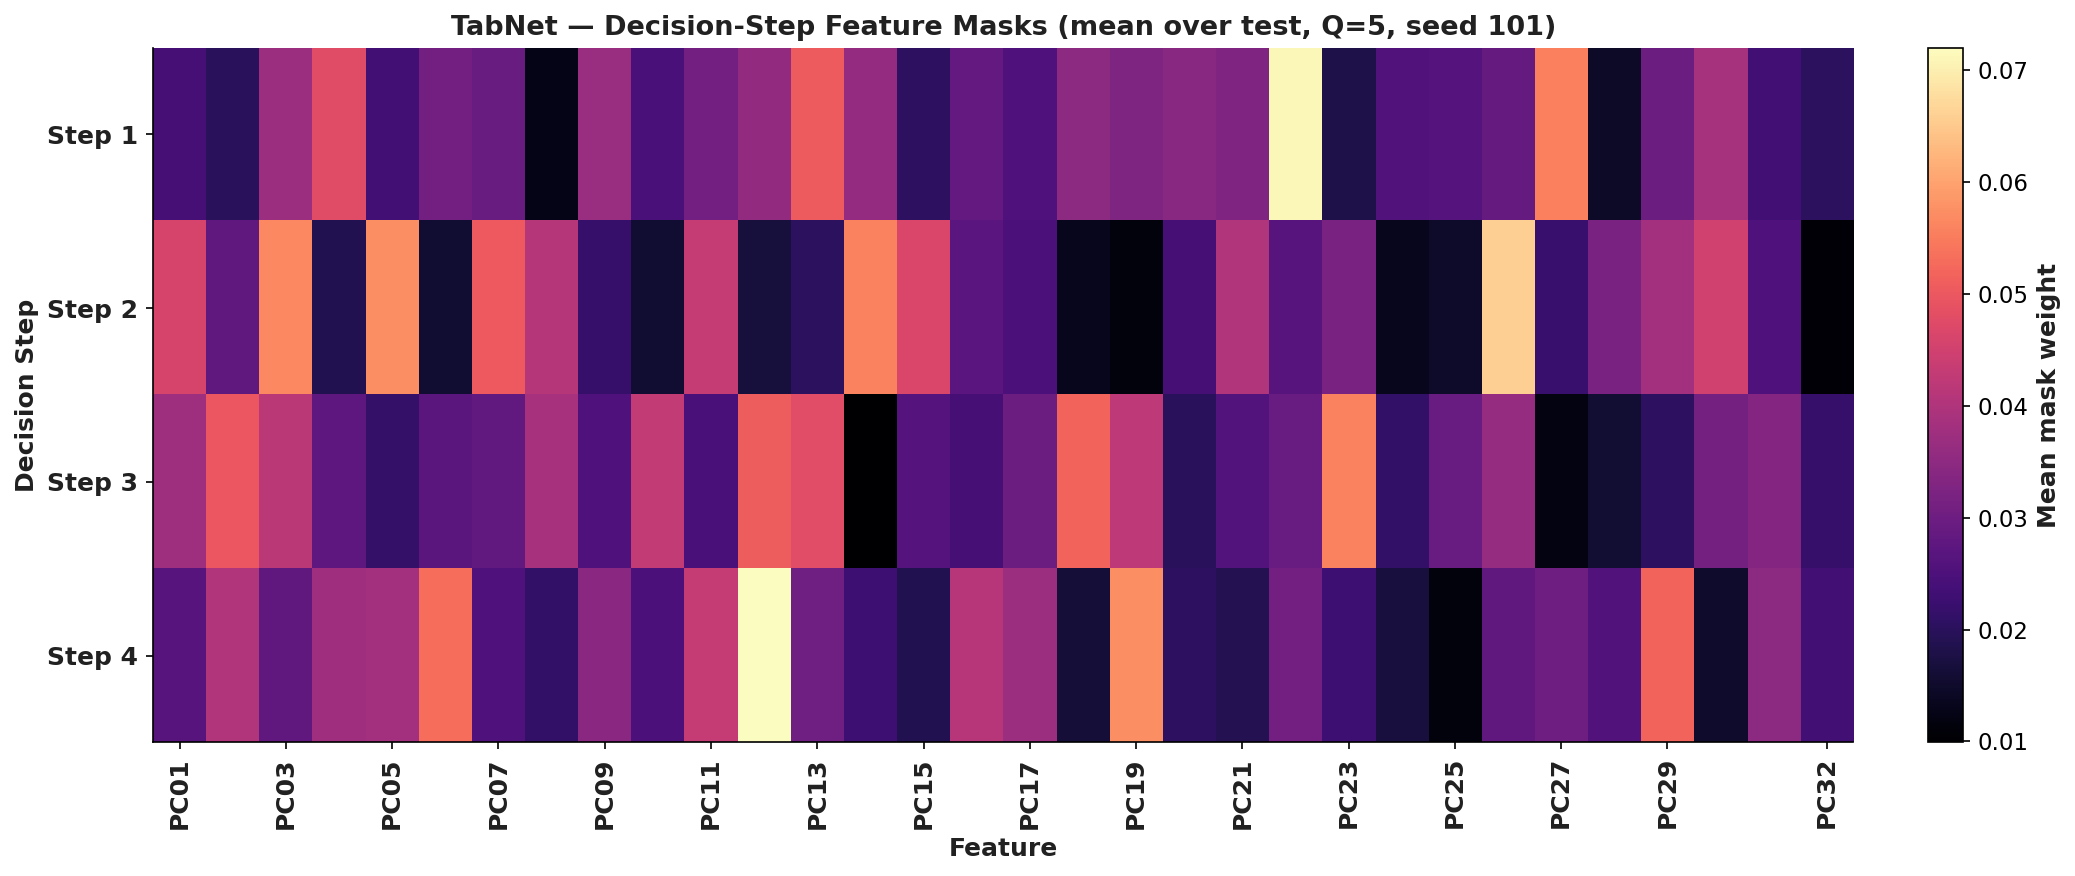

Saved: FIVEQUBITS_reduced/figs/OD-IDS2022/QuantumTabNet/Q5/seed_101/tabnet_masks_step_mean.png


In [ ]:
# ================= 2) DECISION-STEP MASKS (heatmap, clearer + bold labels) ===========================
step_avg = np.vstack([to_numpy(m).mean(axis=0) for m in masks])  # (n_steps, n_features)
step_labels = [f"Step {i+1}" for i in range(step_avg.shape[0])]

# Make the figure larger 
fig = plt.figure(figsize=(max(14, 0.35*n_features), max(6, 0.4*len(step_labels))))
ax = fig.add_subplot(111)

# Plot heatmap
im = ax.imshow(step_avg, aspect="auto", cmap="magma", interpolation="nearest")

# --- Axis formatting ---
# Y-axis
ax.set_yticks(range(len(step_labels)))
ax.set_yticklabels(step_labels, fontsize=12, fontweight="bold", color=PALETTE["annot"])

# X-axis: show ~16 ticks for readability, not all 32
xticks = np.linspace(0, n_features - 1, min(n_features, 16), dtype=int)
ax.set_xticks(xticks)
ax.set_xticklabels([feat_names[i] for i in xticks],
                   rotation=90, fontsize=12, fontweight="bold", color=PALETTE["annot"])

# Axis labels and title (bold for visibility)
ax.set_xlabel("Feature", fontsize=12, fontweight="bold", color=PALETTE["annot"])
ax.set_ylabel("Decision Step", fontsize=12, fontweight="bold", color=PALETTE["annot"])
ax.set_title(f"TabNet — Decision-Step Feature Masks (mean over test, Q={Q}, seed {SEED})",
             fontsize=13, fontweight="bold", color=PALETTE["annot"])

# --- Colorbar ---
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Mean mask weight", fontsize=12, fontweight="bold", color=PALETTE["annot"])
cbar.ax.tick_params(labelsize=11)

# --- Layout ---
plt.tight_layout()

# --- Save ---
out = fig_stem(DATASET, MODEL, Q, f"seed_{SEED}", "tabnet_masks_step_mean")
savefig_both(fig, out, {
    "dataset": DATASET,
    "model": MODEL,
    "qubits": Q,
    "seed_or_tag": f"seed_{SEED}",
    "plot_type": "tabnet_mask_steps"
})
print("Saved:", out.with_suffix(".png"))


In [ ]:
# ================= HEATMAP (Larger Image + Much Larger Fonts + No Title + No Bold) ===================
import numpy as np
import matplotlib.pyplot as plt

# step_avg: (n_steps, n_features)
step_avg = np.vstack([to_numpy(m).mean(axis=0) for m in masks])
step_labels = [f"Step {i+1}" for i in range(step_avg.shape[0])]
n_steps, n_features = step_avg.shape

# ================= FIGURE SIZE + DPI =================
fig = plt.figure(
    figsize=(max(24, 0.70 * n_features),     
             max(14, 0.70 * n_steps)),       
    dpi=550                                   
)
ax = fig.add_subplot(111)

# ================= HEATMAP =================
im = ax.imshow(step_avg, aspect="auto", cmap="magma", interpolation="nearest")

# ================= AXIS TICKS (NO BOLD, BIGGER FONTS) =================
ax.set_yticks(range(len(step_labels)))
ax.set_yticklabels(step_labels, fontsize=30, color=PALETTE["annot"])    

xticks = np.linspace(0, n_features - 1, min(n_features, 16), dtype=int)
ax.set_xticks(xticks)
ax.set_xticklabels(
    [feat_names[i] for i in xticks],
    rotation=90,
    fontsize=30,                                  
    color=PALETTE["annot"]
)

# ================= AXIS LABELS (NO BOLD, BIGGER FONTS) =================
ax.set_xlabel("Feature", fontsize=34, color=PALETTE["annot"])           
ax.set_ylabel("Decision Step", fontsize=34, color=PALETTE["annot"])     

# ax.set_title(...)

# ================= COLORBAR (NO BOLD, BIGGER FONTS) =================
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Mean mask weight", fontsize=30, color=PALETTE["annot"])   
cbar.ax.tick_params(labelsize=26)                                         
# ================= LAYOUT =================
plt.tight_layout()

# ================= SAVE FILES =================
stem = "newtabnetnew"
out = fig_stem(DATASET, MODEL, Q, f"seed_{SEED}", stem)

png_path = out.with_suffix(".png")
pdf_path = out.with_suffix(".pdf")
eps_path = out.with_suffix(".eps")

fig.savefig(png_path, dpi=600, bbox_inches="tight", transparent=True)
fig.savefig(pdf_path, dpi=600, bbox_inches="tight", transparent=True)
fig.savefig(eps_path, dpi=600, bbox_inches="tight", transparent=True, format="eps")

print("Saved PNG:", png_path)
print("Saved PDF:", pdf_path)
print("Saved EPS:", eps_path)


Saved PNG: FIVEQUBITS_reduced/figs/OD-IDS2022/QuantumTabNet/Q5/seed_101/newtabnetnew.png
Saved PDF: FIVEQUBITS_reduced/figs/OD-IDS2022/QuantumTabNet/Q5/seed_101/newtabnetnew.pdf
Saved EPS: FIVEQUBITS_reduced/figs/OD-IDS2022/QuantumTabNet/Q5/seed_101/newtabnetnew.eps


In [39]:
import os
print(os.getcwd())


/home/g202319370/mydesktop/DATASETS
